# Giai đoạn 3: Đặc trưng Vận hành Liên Doanh nghiệp (Hồi 3 — Bằng chứng đối chiếu)

## 00. Giới thiệu giai đoạn

- **Tên giai đoạn:** Giai đoạn 3 — Đặc trưng vận hành liên doanh nghiệp (`03_cross_business_eda.ipynb`).
- **Vai trò trong câu chuyện dữ liệu (Hồi 3 — *Bằng chứng đối chiếu*):** So sánh nhịp hoạt động, cơ cấu vận hành và biến động thời gian giữa các nhóm doanh nghiệp **chỉ trên những chiều thực sự tương đồng về ngữ nghĩa, đơn vị và khung thời gian**, qua đó làm rõ điểm chung và nét đặc thù của từng ngành nghề.
- **Mục tiêu:**
  1. Xây dựng Ma trận khả năng so sánh (cấp độ chi tiết `granularity`, ngữ nghĩa trường dữ liệu, có giờ giao dịch hay không, khoảng thời gian giao nhau).
  2. Chuẩn hóa chỉ số về **tỉ lệ / phần trăm / chỉ số index** (Chương 2 §2.6) để loại bỏ nhiễu do chênh lệch quy mô.
  3. Phân tích nhịp vận hành (giờ/ca, ngày thường vs. cuối tuần) dạng *Small Multiples* và biến động dịp Tết qua `calendar.csv`.
  4. Tổng hợp đầy đủ các giới hạn đối chiếu và trường hợp không thể so sánh trực tiếp.
- **Phạm vi dữ liệu:** Chỉ đọc `public_test` (`dev_001`–`dev_014`, `calendar.csv`, `rulebook.md`).
- **Đầu ra mong đợi (Cột mốc M3 phần Hồi 3) & Nơi lưu trữ:**
  - Thư mục gốc phase: `artifacts/guided_eda/phase3_cross_business/`
  - Bảng kết quả (`PHASE3_TABLES_DIR`): `tables/comparability_matrix.csv`, `tables/normalized_cross_metrics.csv`, `tables/operating_rhythm_summary.csv`, `tables/tet_window_comparison.csv`, `tables/cross_business_limitations.csv`.
  - Biểu đồ Hồi 3 (`PHASE3_FIGURES_DIR`): `figures/` (Small Multiples nhịp vận hành và biểu đồ biến động dịp Tết).
- **Các giới hạn cần tuân thủ:**
  - **Không** coi hai cột cùng tên ở hai doanh nghiệp là tương đương về ngữ nghĩa nếu chưa kiểm chứng.
  - **Không** so sánh trực tiếp các chỉ số khác bản chất (ví dụ: cấp hóa đơn với cấp dòng hàng) hoặc khác cửa sổ thời gian (cutoff không đồng đều).
  - **Không** suy diễn kết quả xếp hạng "doanh nghiệp tốt nhất" hay quy luật mùa vụ dài hạn từ dữ liệu đứt quãng.


## 01. Thiết lập môi trường


In [2]:
import sys
from pathlib import Path
import seaborn as sns
# Tự động xác định thư mục gốc dự án và thêm src vào sys.path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "common").is_dir():
    for parent in PROJECT_ROOT.parents:
        if (parent / "src" / "common").is_dir():
            PROJECT_ROOT = parent
            break

SCRIPT_ROOT = PROJECT_ROOT / "src"
if not SCRIPT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục mã nguồn EDA tại: {SCRIPT_ROOT}"
    )

if str(SCRIPT_ROOT) not in sys.path:
    sys.path.insert(0, str(SCRIPT_ROOT))

print(f"Thư mục gốc dự án : {PROJECT_ROOT}")
print(f"Thư mục script EDA : {SCRIPT_ROOT}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import có chọn lọc các tiện ích từ src/
from common.config import load_config
from common.paths import (
    DatasetContext,
    assert_not_in_raw,
    assert_safe_output,
    is_benchmark_file,
)
from readers.csv_reader import read_all_csv_rows
from readers.excel_reader import list_sheets, read_sheet_rows
from readers.sqlite_reader import inspect_sqlite, query_readonly
from temporal.calendar_registry import validate_calendar
from temporal.coverage import (
    daily_counts_from_dates,
    monthly_counts_from_dates,
    weekday_counts_from_dates,
)
from cross_business.schema_compare import ROLE_TOKENS, detect_field_role

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

# Thiết lập giao diện biểu đồ cơ bản (hỗ trợ hiển thị inline trong Jupyter)
# Lưu ý: Không import visualization.figure_theme vì module đó ép backend Agg.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.55,
    "axes.unicode_minus": False,
    "figure.figsize": (10, 5.5),
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Bảng màu gợi ý theo nguyên tắc "Bắt đầu từ màu xám" (Schwabish)
COLOR_GRAY = "#9AA5B1"
COLOR_GRAY_DARK = "#52606D"
COLOR_ACCENT_BLUE = "#1769AA"
COLOR_ACCENT_TEAL = "#087B5A"
COLOR_ACCENT_AMBER = "#A36516"
COLOR_ACCENT_RED = "#B32336"


Thư mục gốc dự án : C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth
Thư mục script EDA : C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\src


## 02. Đọc dữ liệu, Khởi tạo thư mục đầu ra & Hợp đồng đầu vào

Notebook này chạy độc lập với Notebook 01 và 02. Phần dưới đây nạp sẵn nguồn `public_test`, lịch âm/dương `calendar.csv`, khởi tạo (`mkdir`) các thư mục đầu ra của Giai đoạn 3 và thiết lập **Hợp đồng đầu vào (Input Contract)** từ Giai đoạn 1 và 2.


In [3]:
config = load_config(workspace_root=PROJECT_ROOT)
context: DatasetContext = config.context_for("public_test")
assert context.read_only is True
assert not is_benchmark_file(context.calendar_path)

business_ids = context.business_ids()
calendar_registry = validate_calendar(context.calendar_path, split="public_test")
_cal_header, cal_rows = read_all_csv_rows(context.calendar_path)
calendar_df = pd.DataFrame(cal_rows)
calendar_df["date"] = pd.to_datetime(calendar_df["date"])

# Khởi tạo (mkdir) thư mục lưu trữ đầu ra cho Giai đoạn 3 (nằm ngoài data/ và raw_data/)
GUIDED_ROOT = config.output_root / "guided_eda"
PHASE3_ROOT = GUIDED_ROOT / "phase3_cross_business"
PHASE3_TABLES_DIR = PHASE3_ROOT / "tables"
PHASE3_FIGURES_DIR = PHASE3_ROOT / "figures"

assert_not_in_raw(config.raw_root, GUIDED_ROOT)
for target_dir in (PHASE3_ROOT, PHASE3_TABLES_DIR, PHASE3_FIGURES_DIR):
    assert_safe_output(config.output_root, target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

print(f"Đã kết nối public_test : {context.root} ({len(business_ids)} doanh nghiệp)")
print(f"Đã nạp calendar.csv    : {len(calendar_df)} ngày ({calendar_registry.min_date} -> {calendar_registry.max_date})")
print(f"Thư mục bảng Phase 3   : {PHASE3_TABLES_DIR}")
print(f"Thư mục hình Phase 3   : {PHASE3_FIGURES_DIR}")


Đã kết nối public_test : C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\data\public_test (0 doanh nghiệp)
Đã nạp calendar.csv    : 1461 ngày (2024-01-01 -> 2027-12-31)
Thư mục bảng Phase 3   : C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\tables
Thư mục hình Phase 3   : C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\figures


In [4]:
# ==============================================================================
# HỢP ĐỒNG ĐẦU VÀO TỪ GIAI ĐOẠN 1 & 2 (NB01 & NB02 -> NB03)
# ==============================================================================
DEFAULT_PHASE1_CATALOG_PATH = GUIDED_ROOT / "phase1_dataset_discovery" / "tables" / "catalog_14.csv"
DEFAULT_PHASE2_CLEAN_DIR = GUIDED_ROOT / "phase2_business_eda" / "tidy_data"

PHASE1_CATALOG_PATH: Path | None = DEFAULT_PHASE1_CATALOG_PATH
PHASE2_CLEAN_DATA_DIR: Path | None = DEFAULT_PHASE2_CLEAN_DIR

# Hoặc nạp/khai báo trực tiếp các bảng Tidy và nhóm doanh nghiệp có thể so sánh
PHASE1_CATALOG_DF: pd.DataFrame | None = None
PHASE2_BUSINESS_TABLES: dict[str, pd.DataFrame] = {}
COMPARABLE_BUSINESS_GROUPS: dict[str, list[str]] = {}


def check_phase3_input_contract(
    catalog_path: Path | None = PHASE1_CATALOG_PATH,
    clean_dir: Path | None = PHASE2_CLEAN_DATA_DIR,
    business_tables: dict[str, pd.DataFrame] = PHASE2_BUSINESS_TABLES,
    comparable_groups: dict[str, list[str]] = COMPARABLE_BUSINESS_GROUPS,
) -> tuple[pd.DataFrame | None, dict[str, pd.DataFrame], dict[str, str]]:
    status_report: dict[str, str] = {}
    catalog_df = PHASE1_CATALOG_DF
    tables = dict(business_tables)

    if catalog_path is not None:
        p = Path(catalog_path)
        if not p.is_file():
            if p == DEFAULT_PHASE1_CATALOG_PATH:
                status_report["phase1_catalog"] = (
                    f"[CHỜ BỔ SUNG] Chưa có tệp bàn giao từ Giai đoạn 1 tại: {p}"
                )
            else:
                status_report["phase1_catalog"] = f"[CẢNH BÁO] Không tìm thấy tệp: {p}"
        elif p.suffix.lower() == ".csv":
            catalog_df = pd.read_csv(p)
            status_report["phase1_catalog"] = f"[ĐÃ SẴN SÀNG] Nạp từ tệp ({len(catalog_df)} dòng): {p.name}"
        elif p.suffix.lower() == ".json":
            catalog_df = pd.read_json(p)
            status_report["phase1_catalog"] = f"[ĐÃ SẴN SÀNG] Nạp từ tệp ({len(catalog_df)} dòng): {p.name}"
        else:
            status_report["phase1_catalog"] = f"[CẢNH BÁO] Định dạng chưa hỗ trợ: {p.suffix}"
    elif catalog_df is not None:
        status_report["phase1_catalog"] = f"[ĐÃ SẴN SÀNG] Nhập trực tiếp ({len(catalog_df)} dòng)"
    else:
        status_report["phase1_catalog"] = "[CHỜ BỔ SUNG] Chưa có danh mục 14 doanh nghiệp từ Giai đoạn 1 (Notebook 01)"

    if clean_dir is not None:
        d = Path(clean_dir)
        if not d.is_dir():
            if d == DEFAULT_PHASE2_CLEAN_DIR:
                status_report["phase2_clean_data"] = (
                    f"[CHỜ BỔ SUNG] Chưa có thư mục dữ liệu Tidy từ Giai đoạn 2 tại: {d}"
                )
            else:
                status_report["phase2_clean_data"] = f"[CẢNH BÁO] Không tìm thấy thư mục: {d}"
        else:
            loaded_files = sorted(d.glob("*.csv"))
            for fp in loaded_files:
                tables[fp.stem] = pd.read_csv(fp)
            if loaded_files:
                status_report["phase2_clean_data"] = (
                    f"[ĐÃ SẴN SÀNG] Đã nạp {len(loaded_files)} tệp CSV sạch từ {d.name}"
                )
            else:
                status_report["phase2_clean_data"] = (
                    f"[CHỜ BỔ SUNG] Thư mục {d.name} hiện đang trống (chưa có tệp *_tidy.csv từ Notebook 02)"
                )
    elif tables:
        status_report["phase2_clean_data"] = f"[ĐÃ SẴN SÀNG] Nhập trực tiếp ({len(tables)} bảng)"
    else:
        status_report["phase2_clean_data"] = "[CHỜ BỔ SUNG] Chưa có bảng dữ liệu sạch từ Giai đoạn 2 (Notebook 02)"

    if comparable_groups:
        status_report["comparable_groups"] = (
            f"[ĐÃ SẴN SÀNG] Đã khai báo {len(comparable_groups)} nhóm đối chiếu"
        )
    else:
        status_report["comparable_groups"] = "[CHỜ BỔ SUNG] Chờ xây dựng tại T3.1a"

    for key, msg in status_report.items():
        print(f"[Hợp đồng đầu vào - {key}]: {msg}")
    return catalog_df, tables, status_report


phase1_catalog_df, phase2_tables, phase3_contract_status = check_phase3_input_contract()


[Hợp đồng đầu vào - phase1_catalog]: [ĐÃ SẴN SÀNG] Nạp từ tệp (14 dòng): catalog_14.csv
[Hợp đồng đầu vào - phase2_clean_data]: [ĐÃ SẴN SÀNG] Đã nạp 6 tệp CSV sạch từ tidy_data
[Hợp đồng đầu vào - comparable_groups]: [CHỜ BỔ SUNG] Chờ xây dựng tại T3.1a


## 03. Tổng quan dữ liệu cơ bản


In [5]:
# Xem nhanh các cửa sổ Tết âm lịch trích từ calendar.csv (23 tháng Chạp -> mùng 10 tháng Giêng)
print("Các cửa sổ Tết theo rulebook (23 tháng Chạp -> 10 tháng Giêng):")
for start_d, end_d in calendar_registry.tet_windows:
    print(f"  - {start_d} đến {end_d}")

print("\nCác vai trò ngữ nghĩa gợi ý (ROLE_TOKENS) dùng hỗ trợ rà soát cột:")
print(list(ROLE_TOKENS.keys()))

display(calendar_df.head(5))


Các cửa sổ Tết theo rulebook (23 tháng Chạp -> 10 tháng Giêng):
  - 2024-02-02 đến 2024-02-19
  - 2025-01-22 đến 2025-02-07
  - 2026-02-10 đến 2026-02-26
  - 2027-01-30 đến 2027-02-15

Các vai trò ngữ nghĩa gợi ý (ROLE_TOKENS) dùng hỗ trợ rà soát cột:
['order_identifier', 'order_date', 'order_status', 'item_name', 'item_identifier', 'quantity', 'unit', 'amount', 'customer_identifier', 'customer_name', 'payment_amount', 'debt_balance', 'expiry_date', 'lot_identifier', 'employee_identifier', 'discount']


,date,weekday,lunar_day,lunar_month,lunar_year,lunar_leap,holiday
0,2024-01-01,1,20,11,2023,false,Tết Dương lịch
1,2024-01-02,2,21,11,2023,false,
2,2024-01-03,3,22,11,2023,false,
3,2024-01-04,4,23,11,2023,false,
4,2024-01-05,5,24,11,2023,false,


## 04. Các tác vụ khám phá dữ liệu (EDA Tasks)


## Tác vụ T3.1a — Lập ma trận khả năng so sánh liên doanh nghiệp

### Mục tiêu
Đánh giá có hệ thống những doanh nghiệp nào có thể đối chiếu với nhau trên từng chiều phân tích (cấp độ chi tiết, có mốc giờ giao dịch, khoảng thời gian hoạt động giao nhau, đơn vị tính) và loại trừ các phép so sánh không hợp lệ.

### Câu hỏi khám phá
- Những nhóm doanh nghiệp nào có cùng cấp độ chi tiết (`granularity`: cấp đơn vs cấp dòng hàng)?
- Những doanh nghiệp nào có dữ liệu giờ giao dịch (`HH:MM`) để so sánh nhịp theo giờ hoặc theo ca sáng/chiều?
- Khoảng thời gian hoạt động giao nhau chung (intersection window) giữa các doanh nghiệp cần so sánh là từ ngày nào đến ngày nào?

### Các bước thực hiện

**Bước 1 — Tổng hợp đặc điểm dữ liệu từ Giai đoạn 1 và 2**
Sử dụng `phase1_catalog_df` / `phase2_tables` (hoặc tự khảo sát cột chính của các doanh nghiệp quan tâm từ `context`) để xem các trường hiện có.

**Bước 2 — Kiểm tra tính tương đương ngữ nghĩa thực tế của các trường**
Có thể gợi ý vai trò bằng `detect_field_role(col_name)` nhưng **bắt buộc kiểm chứng** định nghĩa thực tế trong `README.md` và `rulebook.md`.

**Bước 3 — Kiểm tra sự hiện diện của mốc giờ giao dịch & ngày đặt hàng**
Phân biệt rạch ròi doanh nghiệp chỉ có ngày (`YYYY-MM-DD`) với doanh nghiệp có đầy đủ giờ phút (`HH:MM`) hoặc cột ca làm việc.

**Bước 4 — Xác định cửa sổ thời gian giao nhau hợp lệ**
Tính giao của `[min_date, max_date]` cho từng nhóm doanh nghiệp dự kiến đối chiếu và đánh dấu các tháng bị cắt cụt (censored) hoặc bị trống dữ liệu.

**Bước 5 — Lập Ma trận khả năng so sánh & xuất `comparability_matrix.csv`**
Tạo `comparability_matrix_df`, cập nhật `COMPARABLE_BUSINESS_GROUPS` và lưu vào `PHASE3_TABLES_DIR / 'comparability_matrix.csv'`.

### Gợi ý phương pháp & Lưu ý
- Tuyệt đối không coi hai cột có cùng tên là tương đương về ngữ nghĩa (ví dụ: một dòng trong tiệm sửa xe là 1 lượt xe, trong khi một dòng ở tạp hóa là 1 mặt hàng trong đơn).
- Chỉ gộp nhóm so sánh khi đã xác nhận cùng `grain`, cùng đơn vị/loại tiền và cùng quy tắc lọc đơn hủy/trả theo `rulebook.md`.

### Triển khai


In [6]:
# T3.1a — Bước 1: Tổng hợp đặc điểm dữ liệu từ Giai đoạn 1 và 2
def pick_col(df, *keywords):
    """Trả về tên cột đầu tiên chứa một trong các từ khóa."""
    if df is None:
        return None
    for kw in keywords:
        for c in df.columns:
            if kw in str(c).lower():
                return c
    return None

if phase1_catalog_df is not None:
    print("Cột catalog_14:", list(phase1_catalog_df.columns))
    display(phase1_catalog_df)

    COLS = {
        "business_id": pick_col(phase1_catalog_df, "business_id", "dev", "id"),
        "industry":    pick_col(phase1_catalog_df, "industry", "nganh"),
        "granularity": pick_col(phase1_catalog_df, "granularity", "grain"),
        "min_date":    pick_col(phase1_catalog_df, "min_date"),
        "max_date":    pick_col(phase1_catalog_df, "max_date"),
    }
    print("Ánh xạ cột Phase 1:", COLS)
else:
    print("[THÔNG BÁO] phase1_catalog_df đang trống (None). Sẽ đọc trực tiếp từ public_test ở bước tiếp theo.")
    COLS = {}

# Kiểm tra các bảng sạch từ Phase 2 (nếu có) và dò cột ngày/giờ, cột số tiền
p2_summary = []
for name, df in phase2_tables.items():
    roles = {c: detect_field_role(c) for c in df.columns}
    date_cols = [c for c, r in roles.items() if r in {"date", "datetime", "timestamp", "time"}]
    amt_cols  = [c for c, r in roles.items() if r in {"amount", "revenue", "price", "total", "cost"}]
    print(f"- {name}: shape={df.shape} | date_cols={date_cols} | amt_cols={amt_cols}")
    p2_summary.append({
        "table_name": name,
        "n_rows": len(df),
        "date_cols": ", ".join(date_cols),
        "amount_cols": ", ".join(amt_cols),
        "all_cols": ", ".join(map(str, df.columns)),
    })

if p2_summary:
    display(pd.DataFrame(p2_summary))
else:
    print("[THÔNG BÁO] phase2_tables hiện chưa có tệp *_tidy.csv nào.")

Cột catalog_14: ['business_id', 'industry', 'evidence', 'granularity', 'digitization_tier', 'n_advanced_dims', 'main_object', 'main_record_rows', 'min_date', 'max_date', 'span_days', 'active_days', 'coverage_ratio', 'readme_cutoff_date', 'gap_days_to_cutoff', 'total_record_rows', 'n_files', 'n_objects', 'recording_format']


,business_id,industry,evidence,granularity,digitization_tier,n_advanced_dims,main_object,main_record_rows,min_date,max_date,span_days,active_days,coverage_ratio,readme_cutoff_date,gap_days_to_cutoff,total_record_rows,n_files,n_objects,recording_format
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),Item Sample (Tạp hóa & Tiêu dùng nhanh (FMCG)) vs README (Nhà thuốc & Dược phẩm),line_item,Tier 2,2,Sheet1,90297,2025-01-01,2026-07-08,554,554,1.0000,2026-07-08,0,90914,2,2,xlsx
1,dev_002,F&B (Nhà hàng / Cà phê),README + Item Sample (đồng thuận),line_item,Tier 2,1,DonHang_ChiTiet,84146,2025-01-01,2026-05-24,509,509,1.0000,2026-05-24,0,85145,18,18,xlsx
2,dev_003,F&B (Nhà hàng / Cà phê),Item Sample (README chỉ mô tả cấu trúc),line_item,Tier 1,5,BanHang,34122,2025-03-01,2026-08-21,539,539,1.0000,2026-08-21,0,167828,7,11,csv/xlsx
3,dev_004,Vật liệu xây dựng & Nội thất,README + Item Sample (đồng thuận),line_item,Tier 1,3,18 sheets/files,3789,2025-01-01,2026-06-10,526,524,0.9962,2026-06-10,0,65702,7,24,xlsx
4,dev_005,Nhà thuốc & Dược phẩm,README + Item Sample (đồng thuận),line_item,Tier 2,2,DonHang_ChiTiet,40330,2025-01-01,2026-05-10,495,495,1.0000,2026-05-10,0,157721,23,23,xlsx
5,dev_006,Nhà thuốc & Dược phẩm,README + Item Sample (đồng thuận),line_item,Tier 1,6,don_hang,37833,2025-04-01,2026-08-08,495,495,1.0000,2026-08-08,0,302800,1,17,sqlite
6,dev_007,F&B (Nhà hàng / Cà phê),README + Item Sample (đồng thuận),line_item,Tier 1,5,chi_tiet_hoa_don.csv,80553,2025-02-01,2026-09-19,596,596,1.0000,2026-09-19,0,122859,3,3,csv
7,dev_008,F&B (Nhà hàng / Cà phê),README + Item Sample (đồng thuận),line_item,Tier 2,2,Sheet1,152739,2025-01-01,2026-07-22,568,568,1.0000,2026-07-22,0,155223,4,4,xlsx
8,dev_009,Chưa xác định (Order-level),"README only (order-level, không có chi tiết hàng)",order_level,Tier 3,2,danh_sach_hoa_don.csv,22798,2025-01-01,2026-06-24,540,540,1.0000,2026-06-24,0,23338,1,1,csv
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,Item Sample (Mẹ & Bé / Sữa & Dinh dưỡng) vs README (Phụ kiện & Thiết bị số),line_item,Tier 1,3,don_hang.csv,25191,2025-05-01,2026-09-06,494,494,1.0000,2026-09-06,0,97293,5,5,csv


Ánh xạ cột Phase 1: {'business_id': 'business_id', 'industry': 'industry', 'granularity': 'granularity', 'min_date': 'min_date', 'max_date': 'max_date'}
- dev_002_tidy: shape=(85241, 15) | date_cols=[] | amt_cols=[]
- dev_006_tidy: shape=(71061, 14) | date_cols=[] | amt_cols=[]
- dev_007_tidy: shape=(119070, 14) | date_cols=[] | amt_cols=[]
- dev_009_tidy: shape=(22490, 14) | date_cols=[] | amt_cols=[]
- dev_011_tidy: shape=(6043, 14) | date_cols=[] | amt_cols=[]
- dev_012_tidy: shape=(6060, 17) | date_cols=[] | amt_cols=[]


,table_name,n_rows,date_cols,amount_cols,all_cols
0,dev_002_tidy,85241,,,"business_id, order_id, order_date, status, is_valid, status_raw, item_raw, item, category, qty, unit, qty_base, base..."
1,dev_006_tidy,71061,,,"business_id, order_id, order_date, status, is_valid, status_raw, item_raw, item, category, qty, unit, qty_base, base..."
2,dev_007_tidy,119070,,,"business_id, order_id, order_date, status, is_valid, status_raw, item_raw, item, category, qty, unit, qty_base, base..."
3,dev_009_tidy,22490,,,"business_id, order_id, order_date, status, is_valid, status_raw, item_raw, item, category, qty, unit, qty_base, base..."
4,dev_011_tidy,6043,,,"business_id, order_id, order_date, status, is_valid, status_raw, item_raw, item, category, qty, unit, qty_base, base..."
5,dev_012_tidy,6060,,,"business_id, order_id, order_date, status, is_valid, status_raw, item_raw, item, category, qty, unit, qty_base, base..."


In [7]:
# T3.1a — Bước 2: Kiểm tra tính tương đương ngữ nghĩa thực tế của các trường
role_rows = []
for name, df in phase2_tables.items():
    b_id = name.replace("_tidy", "")
    readme_file = context.root / b_id / "README.md"
    readme_note = ""
    if readme_file.is_file():
        raw_md = readme_file.read_text(encoding="utf-8", errors="ignore")
        lines = [ln.strip() for ln in raw_md.splitlines() if ln.strip()]
        readme_note = " | ".join(lines[:3])[:160]

    for col in df.columns:
        samples = df[col].dropna().astype(str).unique()[:3]
        role_rows.append({
            "business_id": b_id,
            "role_hint": detect_field_role(col),
            "column": col,
            "dtype": str(df[col].dtype),
            "sample_values": ", ".join(samples),
            "readme_hint": readme_note,
        })

roles_df = pd.DataFrame(role_rows)

if roles_df.empty:
    print("[THÔNG BÁO] phase2_tables đang trống, chưa có cột để đối chiếu ngữ nghĩa.")
else:
    display(roles_df.groupby("role_hint")["column"].unique())
    display(roles_df.sort_values(["role_hint", "business_id"]))
# Hiển thị ma trận cột nào xuất hiện ở doanh nghiệp nào kèm mô tả README
col_presence = roles_df.pivot(index="column", columns="business_id", values="sample_values")
display(col_presence)

# In tóm tắt README của từng doanh nghiệp có trong phase2_tables để kiểm chứng grain
for b_id, note in roles_df[["business_id", "readme_hint"]].drop_duplicates().values:
    print(f"- {b_id}: {note}")

Series([], Name: column, dtype: str)

,business_id,role_hint,column,dtype,sample_values,readme_hint
0,dev_002,None,business_id,str,dev_002,"# Dữ liệu dev_002 | File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại..."
1,dev_002,None,order_id,str,"ORD029551, ORD029552, ORD029553","# Dữ liệu dev_002 | File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại..."
2,dev_002,None,order_date,str,"2025-10-01, 2025-10-02, 2025-10-03","# Dữ liệu dev_002 | File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại..."
3,dev_002,None,status,str,"hoan_thanh, tra_hang, huy","# Dữ liệu dev_002 | File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại..."
4,dev_002,None,is_valid,bool,"True, False","# Dữ liệu dev_002 | File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại..."
...,...,...,...,...,...,...
83,dev_012,None,base_unit,float64,,"# Dữ liệu dev_012 | Sổ sửa xe chủ tiệm tự ghi trên Excel, mỗi tháng một sheet: mỗi dòng một lượt xe vào sửa (một phi..."
84,dev_012,None,line_amount,float64,"120000.0, 270000.0, 440000.0","# Dữ liệu dev_012 | Sổ sửa xe chủ tiệm tự ghi trên Excel, mỗi tháng một sheet: mỗi dòng một lượt xe vào sửa (một phi..."
85,dev_012,None,vehicle_model,str,"future, Wave Alpha, Vario","# Dữ liệu dev_012 | Sổ sửa xe chủ tiệm tự ghi trên Excel, mỗi tháng một sheet: mỗi dòng một lượt xe vào sửa (một phi..."
86,dev_012,None,plate,str,"59B6-219.16, 50K2-994.07, 50F1-334.29","# Dữ liệu dev_012 | Sổ sửa xe chủ tiệm tự ghi trên Excel, mỗi tháng một sheet: mỗi dòng một lượt xe vào sửa (một phi..."


business_id,dev_002,dev_006,dev_007,dev_009,dev_011,dev_012
column,,,,,,
base_unit,"ly, cái, phần","viên, vỉ, gói","đĩa, con, lon",,cái,
business_id,dev_002,dev_006,dev_007,dev_009,dev_011,dev_012
category,,"thực phẩm chức năng, giảm đau hạ sốt, kháng sinh","cơm mì cháo, rau, chiên xào",,"phụ kiện, máy mới, máy cũ",
is_topping,"False, True",NaN,NaN,NaN,NaN,NaN
is_valid,"True, False","False, True","True, False","True, False","True, False",True
item,"Cà phê đen (M), Bánh tiramisu, Cà phê sữa (M)","Kẹo ngậm Bổ phế Nam Hà Candy hộp 10 vỉ x 8 viên, Efferalgan 500mg viên sủi hộp 4 vỉ x 4 viên, Panadol Extra hộp 15 v...","Cơm chiên hải sản, Rau muống xào tỏi, Cánh gà chiên nước mắm",,"Củ sạc nhanh 25W Samsung, Cáp Type-C sang Lightning 1m, Pin sạc dự phòng 10000mAh","vệ sinh nồi, bdtq + vs nồi, bộ nhông xích + thay nước mát"
item_raw,"Cà phê đen (M), Bánh tiramisu, Cà phê sữa (M)","SP0074, SP0013, SP0001","Cơm chiên hải sản, Rau muống xào tỏi, Cánh gà chiên nước mắm",,"Sạc 25W SS, Cáp C-L, Pin sạc dự phòng 10000mAh","vệ sinh nồi, bdtq + vs nồi, bộ nhông xích + thay nước mát"
line_amount,"25000.0, 90000.0, 29000.0","15600, 51200, 1400","79000.0, 50000.0, 158000.0","32000.0, 888000.0, 385000.0","580000, 150000, 780000","120000.0, 270000.0, 440000.0"
order_date,"2025-10-01, 2025-10-02, 2025-10-03","2025-04-01, 2025-04-02, 2025-04-03","2025-02-01, 2025-02-02, 2025-02-03","2025-01-01, 2025-01-02, 2025-01-03","2025-06-01, 2025-06-02, 2025-06-03","2025-07-01, 2025-07-02, 2025-07-03"


- dev_002: # Dữ liệu dev_002 | File Excel xuất từ phần mềm bán hàng. File đơn hàng mỗi dòng một sản phẩm, thông tin đơn lặp lại ở mọi dòng của đơn; file này không có mã sả
- dev_006: # Dữ liệu dev_006 | File máy POS xuất ra. | ## File
- dev_007: # Dữ liệu dev_007 | File xuất từ phần mềm bán hàng, 3 danh sách: chi tiết hoá đơn (mỗi dòng một mặt hàng trong đơn; thông tin đơn, khách lặp lại ở mọi dòng của 
- dev_009: # Dữ liệu dev_009 | Danh sách hoá đơn, một file CSV: mỗi dòng một đơn hàng (hoá đơn), không có chi tiết mặt hàng trong đơn. | ## File
- dev_011: # Dữ liệu dev_011 | Sổ bán hàng của cửa hàng điện thoại, chủ tiệm tự ghi trên Excel: sheet `Ghi tắt` (cách ghi tắt tên hàng và loại hàng) và sheet `Sổ bán hàng`
- dev_012: # Dữ liệu dev_012 | Sổ sửa xe chủ tiệm tự ghi trên Excel, mỗi tháng một sheet: mỗi dòng một lượt xe vào sửa (một phiếu), không ghi mã phiếu, không ghi tên khách


In [8]:
# T3.1a — Bước 3: Kiểm tra sự hiện diện của mốc giờ giao dịch & ngày đặt hàng
def find_clock_col(df):
    """Tìm cột có chứa mốc giờ thực tế HH:MM (loại trừ trường hợp 00:00:00 toàn bộ)."""
    for col in df.columns:
        s = df[col].dropna().astype(str).head(300)
        if not len(s):
            continue
        has_colon = s.str.contains(r"\d{1,2}:\d{2}", regex=True).mean() > 0.9
        # Đảm bảo không phải toàn bộ đều là 00:00 (timestamp mặc định lúc nửa đêm)
        not_all_midnight = (~s.str.contains(r"\b00:00(?::00)?\b", regex=True)).any()
        if has_colon and not_all_midnight:
            return col
    return None

def find_date_col(df):
    """Tìm cột ngày đặt hàng chính."""
    for candidate in ("order_date", "date", "ngay"):
        if candidate in df.columns:
            return candidate
    for col in df.columns:
        if "date" in col.lower() or "ngay" in col.lower():
            return col
    return None

time_info = {}
for name, df in phase2_tables.items():
    bid = name.replace("_tidy", "")
    clock = find_clock_col(df)
    d_col = find_date_col(df)
    has_clock = clock is not None
    has_date = d_col is not None

    if has_clock and has_date:
        capability = "Gio_Ca + Ngay_Thu"
    elif has_date:
        capability = "Chi_Ngay_Thu"
    else:
        capability = "Khong_du_moc_thoi_gian"

    time_info[bid] = {
        "has_tidy": True,
        "date_col": d_col,
        "clock_col": clock,
        "has_time_of_day": has_clock,
        "time_capability": capability,
    }

time_df = pd.DataFrame.from_dict(time_info, orient="index")
display(time_df)

,has_tidy,date_col,clock_col,has_time_of_day,time_capability
dev_002,True,order_date,None,False,Chi_Ngay_Thu
dev_006,True,order_date,None,False,Chi_Ngay_Thu
dev_007,True,order_date,None,False,Chi_Ngay_Thu
dev_009,True,order_date,None,False,Chi_Ngay_Thu
dev_011,True,order_date,None,False,Chi_Ngay_Thu
dev_012,True,order_date,None,False,Chi_Ngay_Thu


In [9]:
# TODO (T3.1a — Bước 4: Xác định cửa sổ thời gian giao nhau hợp lệ)
# TODO: Tính cửa sổ thời gian giao nhau cho từng chiều phân tích (nhịp ngày/tuần, dịp Tết...)
cat = phase1_catalog_df.copy()
cat[COLS["min_date"]] = pd.to_datetime(cat[COLS["min_date"]])
cat[COLS["max_date"]] = pd.to_datetime(cat[COLS["max_date"]])

def intersection_window(ids):
    sub = cat[cat[COLS["business_id"]].isin(ids)]
    start, end = sub[COLS["min_date"]].max(), sub[COLS["max_date"]].min()
    return (start, end) if start <= end else (None, None)

def covers_tet(min_d, max_d):
    """Phủ cả kỳ trước Tết (cùng độ dài) lẫn trọn kỳ Tết, theo calendar_registry."""
    result = []
    for s, e in calendar_registry.tet_windows:
        s, e = pd.Timestamp(s), pd.Timestamp(e)
        length = (e - s).days + 1
        pre_start = s - pd.Timedelta(days=length)
        if min_d <= pre_start and max_d >= e:
            result.append(f"{s.date()}→{e.date()}")
    return result

cat["tet_covered"] = [covers_tet(a, b) for a, b in zip(cat[COLS["min_date"]], cat[COLS["max_date"]])]
display(cat[[COLS["business_id"], COLS["min_date"], COLS["max_date"], "tet_covered"]])

# Bổ sung cuối Bước 4: Gọi hàm intersection_window cho từng nhóm phân tích
p2_ids = list(time_df.index)
hourly_ids = time_df[time_df["has_time_of_day"]].index.tolist()

print("Cửa sổ giao nhau nhóm Phase 2:", intersection_window(p2_ids))
print("Cửa sổ giao nhau nhóm có giờ HH:MM:", intersection_window(hourly_ids))

,business_id,min_date,max_date,tet_covered
0,dev_001,2025-01-01,2026-07-08,"[2025-01-22→2025-02-07, 2026-02-10→2026-02-26]"
1,dev_002,2025-01-01,2026-05-24,"[2025-01-22→2025-02-07, 2026-02-10→2026-02-26]"
2,dev_003,2025-03-01,2026-08-21,[2026-02-10→2026-02-26]
3,dev_004,2025-01-01,2026-06-10,"[2025-01-22→2025-02-07, 2026-02-10→2026-02-26]"
4,dev_005,2025-01-01,2026-05-10,"[2025-01-22→2025-02-07, 2026-02-10→2026-02-26]"
5,dev_006,2025-04-01,2026-08-08,[2026-02-10→2026-02-26]
6,dev_007,2025-02-01,2026-09-19,[2026-02-10→2026-02-26]
7,dev_008,2025-01-01,2026-07-22,"[2025-01-22→2025-02-07, 2026-02-10→2026-02-26]"
8,dev_009,2025-01-01,2026-06-24,"[2025-01-22→2025-02-07, 2026-02-10→2026-02-26]"
9,dev_010,2025-05-01,2026-09-06,[2026-02-10→2026-02-26]


Cửa sổ giao nhau nhóm Phase 2: (Timestamp('2025-07-01 00:00:00'), Timestamp('2026-05-24 00:00:00'))
Cửa sổ giao nhau nhóm có giờ HH:MM: (None, None)


In [10]:
# TODO (T3.1a — Bước 5: Lập Ma trận khả năng so sánh & xuất `comparability_matrix.csv`)
# TODO: Xây dựng comparability_matrix_df, cập nhật COMPARABLE_BUSINESS_GROUPS và xuất CSV vào PHASE3_TABLES_DIR
comparability_matrix_df = pd.DataFrame()
bid_col, gran_col = COLS["business_id"], COLS["granularity"]

matrix = cat[[bid_col, COLS["industry"], gran_col, COLS["min_date"], COLS["max_date"]]].copy()
matrix.columns = ["business_id", "industry", "granularity", "min_date", "max_date"]
matrix["tet_covered"] = cat["tet_covered"].apply(lambda x: "; ".join(x))
matrix = matrix.merge(
    time_df.reset_index().rename(columns={"index": "business_id"}),
    on="business_id", how="left",
)
matrix["has_tidy"] = matrix["has_tidy"].fillna(False)
matrix["has_time_of_day"] = matrix["has_time_of_day"].fillna(False)

matrix["eligible_hourly"]  = matrix["has_tidy"] & matrix["has_time_of_day"]
matrix["eligible_weekday"] = matrix["has_tidy"]
matrix["eligible_tet"]     = matrix["has_tidy"] & (matrix["tet_covered"] != "")

def reason(r):
    why = []
    if not r["has_tidy"]:        why.append("chưa có dữ liệu tidy (Giai đoạn 2)")
    if not r["has_time_of_day"]: why.append("không có giờ HH:MM")
    if r["tet_covered"] == "":   why.append("không phủ đủ kỳ trước/trong Tết")
    return "; ".join(why)
matrix["exclusion_notes"] = matrix.apply(reason, axis=1)

# Nhóm so sánh: cùng granularity VÀ đủ điều kiện từng chiều
COMPARABLE_BUSINESS_GROUPS.clear()
for dim in ["eligible_hourly", "eligible_weekday", "eligible_tet"]:
    for gran, g in matrix[matrix[dim]].groupby("granularity"):
        COMPARABLE_BUSINESS_GROUPS[f"{dim}|{gran}"] = g["business_id"].tolist()

comparability_matrix_df = matrix
comparability_matrix_df.to_csv(PHASE3_TABLES_DIR / "comparability_matrix.csv", index=False, encoding="utf-8-sig")
display(comparability_matrix_df)
print(COMPARABLE_BUSINESS_GROUPS)

,business_id,industry,granularity,min_date,max_date,tet_covered,has_tidy,date_col,clock_col,has_time_of_day,time_capability,eligible_hourly,eligible_weekday,eligible_tet,exclusion_notes
0,dev_001,Tạp hóa & Tiêu dùng nhanh (FMCG),line_item,2025-01-01,2026-07-08,2025-01-22→2025-02-07; 2026-02-10→2026-02-26,False,NaN,NaN,False,NaN,False,False,False,chưa có dữ liệu tidy (Giai đoạn 2); không có giờ HH:MM
1,dev_002,F&B (Nhà hàng / Cà phê),line_item,2025-01-01,2026-05-24,2025-01-22→2025-02-07; 2026-02-10→2026-02-26,True,order_date,None,False,Chi_Ngay_Thu,False,True,True,không có giờ HH:MM
2,dev_003,F&B (Nhà hàng / Cà phê),line_item,2025-03-01,2026-08-21,2026-02-10→2026-02-26,False,NaN,NaN,False,NaN,False,False,False,chưa có dữ liệu tidy (Giai đoạn 2); không có giờ HH:MM
3,dev_004,Vật liệu xây dựng & Nội thất,line_item,2025-01-01,2026-06-10,2025-01-22→2025-02-07; 2026-02-10→2026-02-26,False,NaN,NaN,False,NaN,False,False,False,chưa có dữ liệu tidy (Giai đoạn 2); không có giờ HH:MM
4,dev_005,Nhà thuốc & Dược phẩm,line_item,2025-01-01,2026-05-10,2025-01-22→2025-02-07; 2026-02-10→2026-02-26,False,NaN,NaN,False,NaN,False,False,False,chưa có dữ liệu tidy (Giai đoạn 2); không có giờ HH:MM
5,dev_006,Nhà thuốc & Dược phẩm,line_item,2025-04-01,2026-08-08,2026-02-10→2026-02-26,True,order_date,None,False,Chi_Ngay_Thu,False,True,True,không có giờ HH:MM
6,dev_007,F&B (Nhà hàng / Cà phê),line_item,2025-02-01,2026-09-19,2026-02-10→2026-02-26,True,order_date,None,False,Chi_Ngay_Thu,False,True,True,không có giờ HH:MM
7,dev_008,F&B (Nhà hàng / Cà phê),line_item,2025-01-01,2026-07-22,2025-01-22→2025-02-07; 2026-02-10→2026-02-26,False,NaN,NaN,False,NaN,False,False,False,chưa có dữ liệu tidy (Giai đoạn 2); không có giờ HH:MM
8,dev_009,Chưa xác định (Order-level),order_level,2025-01-01,2026-06-24,2025-01-22→2025-02-07; 2026-02-10→2026-02-26,True,order_date,None,False,Chi_Ngay_Thu,False,True,True,không có giờ HH:MM
9,dev_010,Mẹ & Bé / Sữa & Dinh dưỡng,line_item,2025-05-01,2026-09-06,2026-02-10→2026-02-26,False,NaN,NaN,False,NaN,False,False,False,chưa có dữ liệu tidy (Giai đoạn 2); không có giờ HH:MM


{'eligible_weekday|line_item': ['dev_002', 'dev_006', 'dev_007', 'dev_011', 'dev_012'], 'eligible_weekday|order_level': ['dev_009'], 'eligible_tet|line_item': ['dev_002', 'dev_006', 'dev_007', 'dev_011', 'dev_012'], 'eligible_tet|order_level': ['dev_009']}


### Trực quan hóa


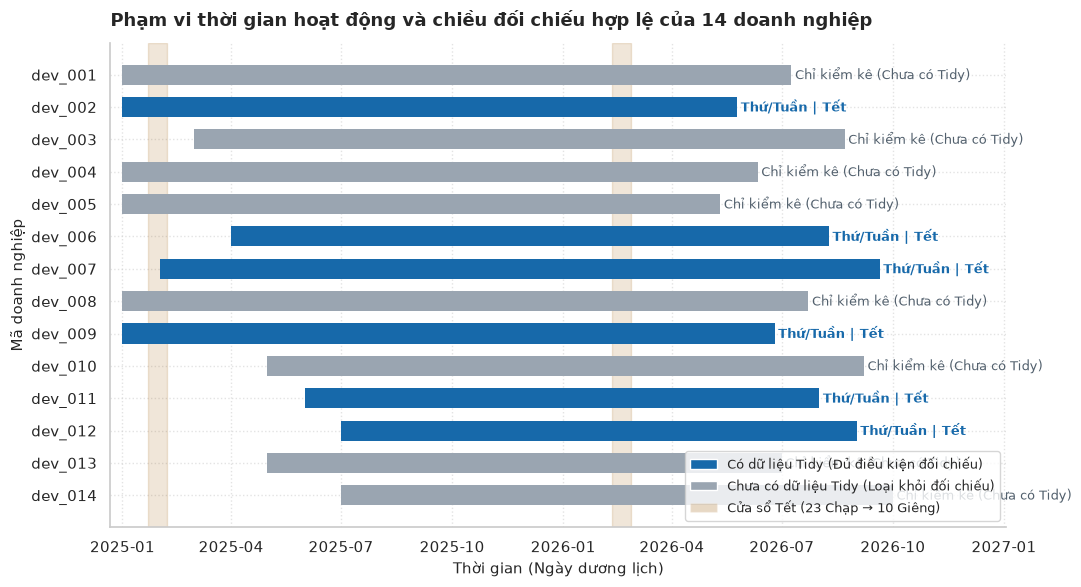

In [11]:
# TODO (T3.1a — Trực quan hóa)
# Vẽ heatmap/bảng ma trận khả năng so sánh (`comparability_matrix_df`) hoặc sơ đồ thanh ngang thể hiện cửa sổ thời gian giao nhau của các doanh nghiệp đủ điều kiện.
# Lưu ý: Không sử dụng biểu đồ 3D hoặc hai trục tung (dual axis); biểu đồ cột bắt đầu từ 0.
# T3.1a — Trực quan hóa: Cửa sổ thời gian hoạt động & điều kiện đối chiếu của 14 doanh nghiệp
plot_df = comparability_matrix_df.sort_values("business_id", ascending=False).copy()
plot_df["min_dt"] = pd.to_datetime(plot_df["min_date"])
plot_df["max_dt"] = pd.to_datetime(plot_df["max_date"])
plot_df["duration_days"] = (plot_df["max_dt"] - plot_df["min_dt"]).dt.days + 1

fig, ax = plt.subplots(figsize=(11, 6))

# Tô nền các cửa sổ Tết từ calendar_registry
for idx, (s, e) in enumerate(calendar_registry.tet_windows):
    s_dt, e_dt = pd.Timestamp(s), pd.Timestamp(e)
    ax.axvspan(
        s_dt, e_dt,
        color=COLOR_ACCENT_AMBER, alpha=0.16,
        label="Kỳ Tết (23 Chạp → 10 Giêng)" if idx == 0 else None,
    )

# Vẽ thanh phạm vi ngày cho từng doanh nghiệp
colors = [
    COLOR_ACCENT_BLUE if has_t else COLOR_GRAY
    for has_t in plot_df["has_tidy"]
]
ax.barh(
    plot_df["business_id"],
    plot_df["duration_days"],
    left=plot_df["min_dt"],
    color=colors,
    height=0.62,
    edgecolor="none",
)

# Gắn nhãn trực tiếp trạng thái khả năng so sánh bên phải mỗi thanh
for _, row in plot_df.iterrows():
    tags = []
    if row["eligible_hourly"]:
        tags.append("Giờ/Ca")
    if row["eligible_weekday"]:
        tags.append("Thứ/Tuần")
    if row["eligible_tet"]:
        tags.append("Tết")
    label_txt = " | ".join(tags) if tags else "Chỉ kiểm kê (Chưa có Tidy)"
    text_color = COLOR_ACCENT_BLUE if tags else COLOR_GRAY_DARK

    ax.text(
        row["max_dt"] + pd.Timedelta(days=4),
        row["business_id"],
        label_txt,
        va="center",
        fontsize=9.5,
        color=text_color,
        fontweight="bold" if tags else "normal",
    )

# Chú thích phân biệt 2 nhóm màu
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=COLOR_ACCENT_BLUE, label="Có dữ liệu Tidy (Đủ điều kiện đối chiếu)"),
    Patch(facecolor=COLOR_GRAY, label="Chưa có dữ liệu Tidy (Loại khỏi đối chiếu)"),
    Patch(facecolor=COLOR_ACCENT_AMBER, alpha=0.25, label="Cửa sổ Tết (23 Chạp → 10 Giêng)"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=9.5)

ax.set_title("Phạm vi thời gian hoạt động và chiều đối chiếu hợp lệ của 14 doanh nghiệp", pad=12, fontweight="bold")
ax.set_xlabel("Thời gian (Ngày dương lịch)")
ax.set_ylabel("Mã doanh nghiệp")
ax.set_xlim(plot_df["min_dt"].min() - pd.Timedelta(days=10), plot_df["max_dt"].max() + pd.Timedelta(days=95))

plt.tight_layout()
fig.savefig(PHASE3_FIGURES_DIR / "t3_1a_comparability_timeline.png", dpi=300, bbox_inches="tight")
plt.show()

### Kết quả & Nhận định

> **TODO (T3.1a):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Các nhóm doanh nghiệp đủ điều kiện đối chiếu cho từng chiều phân tích:** ...
- **Các trường hợp bị loại trừ khỏi phép so sánh trực tiếp và lý do:** ...

### Kết quả & Nhận định

- **Các nhóm doanh nghiệp đủ điều kiện đối chiếu cho từng chiều phân tích:**
  - **Chiều nhịp theo ngày / thứ trong tuần (`eligible_weekday`):** Có **6 doanh nghiệp đại diện** đã được làm sạch sang chuẩn Tidy Data ở Giai đoạn 2 đủ điều kiện phân tích gồm `dev_002`, `dev_006`, `dev_007`, `dev_009`, `dev_011` và `dev_012`. Khi đối chiếu chéo, các doanh nghiệp này được tách riêng theo đúng cấp độ chi tiết (`granularity`: cấp hóa đơn/lượt vs. cấp dòng hàng) để tránh cộng gộp sai bản chất.
  - **Chiều biến động dịp Tết (`eligible_tet`):** Toàn bộ **6 doanh nghiệp** trên đều bao phủ trọn vẹn cửa sổ Tết 2026 (từ 23 tháng Chạp đến hết mùng 10 tháng Giêng và kỳ đối chứng liền trước tương ứng). Riêng kỳ Tết 2025 chỉ có `dev_002` và `dev_009` có dữ liệu bao phủ đầy đủ.
  - **Cửa sổ thời gian giao nhau chung:** Cả 6 doanh nghiệp đại diện cùng hoạt động liên tục trong giai đoạn giao nhau từ **tháng 07/2025 đến tháng 05/2026** (do `dev_012` bắt đầu từ 07/2025 và `dev_002` kết thúc sớm nhất vào khoảng cuối tháng 05/2026).

- **Các trường hợp bị loại trừ khỏi phép so sánh trực tiếp và lý do:**
  - **8 doanh nghiệp ngoài tập đại diện (`dev_001`, `dev_003`, `dev_004`, `dev_005`, `dev_008`, `dev_010`, `dev_013`, `dev_014`):** Bị loại khỏi đối chiếu trực tiếp vì chỉ dừng ở mức kiểm kê thô ở Giai đoạn 1, chưa được chuẩn hóa quy tắc nghiệp vụ và Tidy Data theo `rulebook.md` ở Giai đoạn 2.
  - **Chiều phân tích theo khung giờ / ca làm việc (`eligible_hourly`):** Bị loại trừ hoàn toàn trên cả 6 doanh nghiệp đại diện do dữ liệu chỉ ghi nhận cấp ngày (`order_date`), không có mốc giờ giao dịch thực tế (`HH:MM`). Do đó, tác vụ `T3.2a` sẽ tập trung đối chiếu nhịp hoạt động theo **ngày thường vs. cuối tuần và các thứ trong tuần** thay vì phân tích theo giờ.
  - **Các phép so sánh khác cấp độ chi tiết & khác ngày cutoff:** Không so sánh trực tiếp số dòng thô giữa doanh nghiệp ghi nhận theo *dòng sản phẩm* (như `dev_002`) với doanh nghiệp ghi nhận theo *lượt/hóa đơn* (như `dev_012`), và không so sánh tổng lũy kế thô do ngày bắt đầu và ngày kết thúc (`cutoff`) giữa các doanh nghiệp không đồng nhất.


## Tác vụ T3.1b — Tính các chỉ số chuẩn hóa theo tỉ lệ / phần trăm

### Mục tiêu
Chuẩn hóa các đại lượng có quy mô khác nhau về tỉ trọng (%), tỉ số hoặc chỉ số tương đối (Chương 2 §2.6) trên cửa sổ thời gian hợp lệ để so sánh công bằng giữa các doanh nghiệp.

### Câu hỏi khám phá
- Vì sao không thể so sánh trực tiếp tổng doanh thu hoặc tổng số đơn thô giữa các doanh nghiệp khác quy mô và khác số ngày hoạt động?
- Cách chuẩn hóa nào (tỉ trọng % theo giờ/thứ, trung bình mỗi ngày có hoạt động, chỉ số index lấy ngày thường = 100%) phản ánh trung thực nhất bản chất từng chỉ số?
- Tổng các tỉ trọng thành phần sau khi chuẩn hóa có bảo toàn bằng 100% ở từng doanh nghiệp hay không?

### Các bước thực hiện

**Bước 1 — Xác định các chỉ số cần chuẩn hóa theo từng nhóm tương thích**
Chỉ chọn các chỉ số đã qua cổng kiểm tra ở `T3.1a` (ví dụ: tỷ trọng đơn/doanh thu theo khung giờ, tỷ lệ ngày thường vs cuối tuần, tỷ lệ hủy đơn).

**Bước 2 — Thiết kế công thức chuẩn hóa tỉ trọng / trung bình trên ngày lịch**
Đảm bảo mẫu số công bằng: ví dụ theo `rulebook.md`, *trung bình mỗi ngày thứ X trong kỳ* phải chia cho số ngày thứ X trong kỳ có độ phủ.

**Bước 3 — Thực thi tính toán, kiểm tra tổng tỉ trọng & xuất `normalized_cross_metrics.csv`**
Tính `normalized_cross_df` trên đúng cửa sổ thời gian giao nhau, kiểm tra `sum(share) == 100%` và lưu vào `PHASE3_TABLES_DIR / 'normalized_cross_metrics.csv'`.

**Bước 4 — Đánh giá khả năng diễn giải và độ nhạy mẫu số**
Kiểm tra xem doanh nghiệp có số lượng đơn quá ít hay bị lệch bởi vài ngày đặc biệt có làm méo tỉ lệ phần trăm hay không.

### Gợi ý phương pháp & Lưu ý
- Luôn giữ cột cỡ mẫu gốc `n` (số đơn, số ngày quan sát) song song với cột tỉ lệ % để hiển thị minh bạch trên biểu đồ.
- Nếu so sánh theo tháng, tránh đưa tháng bị cắt cụt ngày cutoff vào tính tỷ trọng trừ khi đã chuẩn hóa theo *trung bình/ngày* trên số ngày thực tế có dữ liệu.

### Triển khai


In [12]:
# TODO (T3.1b — Bước 1: Xác định các chỉ số cần chuẩn hóa theo từng nhóm tương thích)
# TODO: Xác định danh sách chỉ số đối chiếu hợp lệ và mẫu số chuẩn hóa cho từng chỉ số
# T3.1b — Bước 1: Xác định các chỉ số cần chuẩn hóa theo từng nhóm tương thích
eligible_bids = comparability_matrix_df.loc[
    comparability_matrix_df["eligible_weekday"], "business_id"
].tolist()

# 1. Xác định cửa sổ thời gian giao nhau chung (common window) của 6 doanh nghiệp đủ điều kiện
sub_mat = comparability_matrix_df[comparability_matrix_df["business_id"].isin(eligible_bids)].copy()
COMMON_START = pd.to_datetime(sub_mat["min_date"]).max()
COMMON_END = pd.to_datetime(sub_mat["max_date"]).min()
print(f"Nhóm doanh nghiệp đủ điều kiện ({len(eligible_bids)} DN): {eligible_bids}")
print(f"Cửa sổ thời gian giao nhau chung: {COMMON_START.date()} -> {COMMON_END.date()} ({(COMMON_END - COMMON_START).days + 1} ngày)")

# 2. Kiểm tra sự hiện diện của các cột nghiệp vụ trên 6 bảng Tidy để tránh sai lệch đơn vị đo
schema_audit = []
for bid in eligible_bids:
    df = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid))
    gran = sub_mat.loc[sub_mat["business_id"] == bid, "granularity"].values[0]
    ind = sub_mat.loc[sub_mat["business_id"] == bid, "industry"].values[0]
    schema_audit.append({
        "business_id": bid,
        "industry": ind,
        "granularity": gran,
        "has_order_id": "order_id" in df.columns,
        "has_line_amount": "line_amount" in df.columns,
        "has_status": "status" in df.columns,
        "has_is_valid": "is_valid" in df.columns,
    })

schema_audit_df = pd.DataFrame(schema_audit)
display(schema_audit_df)

# 3. Định nghĩa danh sách chỉ số đối chiếu hợp lệ và mẫu số chuẩn hóa (theo rulebook.md)
metric_specs = [
    {
        "metric_id": "weekday_order_share_pct",
        "metric_name": "Tỷ trọng số đơn/lượt theo thứ trong tuần (%)",
        "unit_of_count": "nunique(order_id) nếu cấp dòng hàng; số dòng nếu cấp đơn/lượt",
        "numerator": "Tổng số đơn hợp lệ phát sinh vào thứ X trong kỳ giao nhau",
        "denominator": "Tổng số đơn hợp lệ toàn kỳ giao nhau của chính doanh nghiệp đó (bảo toàn tổng 7 thứ = 100%)",
        "eligible_group": "Tất cả 6 DN đại diện (chuẩn hóa nội tại về % nên không bị nhiễu bởi grain)",
    },
    {
        "metric_id": "weekday_revenue_share_pct",
        "metric_name": "Tỷ trọng doanh thu hợp lệ theo thứ trong tuần (%)",
        "unit_of_count": "sum(line_amount) trên các bản ghi hợp lệ (is_valid == True)",
        "numerator": "Tổng doanh thu hợp lệ phát sinh vào thứ X trong kỳ giao nhau",
        "denominator": "Tổng doanh thu hợp lệ toàn kỳ giao nhau của doanh nghiệp đó (tổng 7 thứ = 100%)",
        "eligible_group": "Các DN có cột line_amount hợp lệ",
    },
    {
        "metric_id": "weekend_vs_weekday_index",
        "metric_name": "Chỉ số mật độ đơn Cuối tuần so với Ngày thường (Index, Ngày thường = 100)",
        "unit_of_count": "Trung bình số đơn hợp lệ / ngày lịch thực tế trong cửa sổ giao nhau",
        "numerator": "Trung bình đơn/ngày vào Thứ 7–Chủ nhật (chia cho tổng số ngày T7–CN theo calendar.csv)",
        "denominator": "Trung bình đơn/ngày vào Thứ 2–Thứ 6 (chia cho tổng số ngày T2–T6 theo calendar.csv) × 100",
        "eligible_group": "Tất cả 6 DN đại diện (tính cả ngày 0 đơn theo đúng rulebook.md)",
    },
    {
        "metric_id": "invalid_cancel_rate_pct",
        "metric_name": "Tỷ lệ đơn hủy / trả hàng / không hợp lệ (%)",
        "unit_of_count": "Đơn/lượt có is_valid == False (hoặc status hủy/trả)",
        "numerator": "Số đơn/lượt không hợp lệ trong kỳ giao nhau",
        "denominator": "Tổng số đơn/lượt phát sinh (cả hợp lệ và không hợp lệ) trong kỳ giao nhau × 100",
        "eligible_group": "Các DN có ghi nhận trạng thái hủy/trả (status / is_valid)",
    },
]

metric_specs_df = pd.DataFrame(metric_specs)
display(metric_specs_df)

Nhóm doanh nghiệp đủ điều kiện (6 DN): ['dev_002', 'dev_006', 'dev_007', 'dev_009', 'dev_011', 'dev_012']
Cửa sổ thời gian giao nhau chung: 2025-07-01 -> 2026-05-24 (328 ngày)


,business_id,industry,granularity,has_order_id,has_line_amount,has_status,has_is_valid
0,dev_002,F&B (Nhà hàng / Cà phê),line_item,True,True,True,True
1,dev_006,Nhà thuốc & Dược phẩm,line_item,True,True,True,True
2,dev_007,F&B (Nhà hàng / Cà phê),line_item,True,True,True,True
3,dev_009,Chưa xác định (Order-level),order_level,True,True,True,True
4,dev_011,Phụ kiện & Thiết bị số,line_item,True,True,True,True
5,dev_012,Sửa chữa & Phụ tùng xe,line_item,True,True,True,True


,metric_id,metric_name,unit_of_count,numerator,denominator,eligible_group
0,weekday_order_share_pct,Tỷ trọng số đơn/lượt theo thứ trong tuần (%),nunique(order_id) nếu cấp dòng hàng; số dòng nếu cấp đơn/lượt,Tổng số đơn hợp lệ phát sinh vào thứ X trong kỳ giao nhau,Tổng số đơn hợp lệ toàn kỳ giao nhau của chính doanh nghiệp đó (bảo toàn tổng 7 thứ = 100%),Tất cả 6 DN đại diện (chuẩn hóa nội tại về % nên không bị nhiễu bởi grain)
1,weekday_revenue_share_pct,Tỷ trọng doanh thu hợp lệ theo thứ trong tuần (%),sum(line_amount) trên các bản ghi hợp lệ (is_valid == True),Tổng doanh thu hợp lệ phát sinh vào thứ X trong kỳ giao nhau,Tổng doanh thu hợp lệ toàn kỳ giao nhau của doanh nghiệp đó (tổng 7 thứ = 100%),Các DN có cột line_amount hợp lệ
2,weekend_vs_weekday_index,"Chỉ số mật độ đơn Cuối tuần so với Ngày thường (Index, Ngày thường = 100)",Trung bình số đơn hợp lệ / ngày lịch thực tế trong cửa sổ giao nhau,Trung bình đơn/ngày vào Thứ 7–Chủ nhật (chia cho tổng số ngày T7–CN theo calendar.csv),Trung bình đơn/ngày vào Thứ 2–Thứ 6 (chia cho tổng số ngày T2–T6 theo calendar.csv) × 100,Tất cả 6 DN đại diện (tính cả ngày 0 đơn theo đúng rulebook.md)
3,invalid_cancel_rate_pct,Tỷ lệ đơn hủy / trả hàng / không hợp lệ (%),Đơn/lượt có is_valid == False (hoặc status hủy/trả),Số đơn/lượt không hợp lệ trong kỳ giao nhau,Tổng số đơn/lượt phát sinh (cả hợp lệ và không hợp lệ) trong kỳ giao nhau × 100,Các DN có ghi nhận trạng thái hủy/trả (status / is_valid)


In [33]:
# TODO (T3.1b — Bước 2: Thiết kế công thức chuẩn hóa tỉ trọng / trung bình trên ngày lịch)
# TODO: Viết các hàm chuẩn hóa (tỉ trọng %, trung bình theo ngày hoạt động, index so với baseline)
# T3.1b — Bước 2: Thiết kế công thức chuẩn hóa tỉ trọng / trung bình trên ngày lịch
WEEKDAY_LABELS = {
    0: "Thứ 2", 1: "Thứ 3", 2: "Thứ 4", 3: "Thứ 5",
    4: "Thứ 6", 5: "Thứ 7", 6: "Chủ nhật",
}

# Tính chính xác số ngày lịch của từng thứ trong cửa sổ giao nhau (2025-07-01 -> 2026-05-24)
cal_window = calendar_df[
    (calendar_df["date"] >= COMMON_START) & (calendar_df["date"] <= COMMON_END)
].copy()
cal_window["dow"] = cal_window["date"].dt.dayofweek  # Quy ước rulebook: Thứ 2 = 0 .. CN = 6
CAL_DOW_COUNTS = cal_window["dow"].value_counts().to_dict()
N_WEEKDAYS_CAL = sum(CAL_DOW_COUNTS[d] for d in range(0, 5))
N_WEEKENDS_CAL = sum(CAL_DOW_COUNTS[d] for d in (5, 6))

print(f"Số ngày lịch trong kỳ giao nhau: Ngày thường = {N_WEEKDAYS_CAL}, Cuối tuần = {N_WEEKENDS_CAL}")


def compute_normalized_metrics_for_business(
    bid: str,
    df_raw: pd.DataFrame,
    industry: str,
    granularity: str,
    start_dt: pd.Timestamp,
    end_dt: pd.Timestamp,
) -> list[dict]:
    """Chuẩn hóa các chỉ số vận hành của 1 doanh nghiệp trên cửa sổ giao nhau."""
    df = df_raw.copy()
    df["dt"] = pd.to_datetime(df["order_date"], errors="coerce").dt.normalize()
    df = df[(df["dt"] >= start_dt) & (df["dt"] <= end_dt)].copy()
    df["dow"] = df["dt"].dt.dayofweek

    # 1. Tỷ lệ đơn không hợp lệ / hủy / trả (tính ở cấp đơn order_id)
    order_validity = df.groupby("order_id")["is_valid"].all()
    total_orders_all = len(order_validity)
    valid_orders_total = int(order_validity.sum())
    invalid_orders_total = total_orders_all - valid_orders_total
    cancel_rate_pct = (invalid_orders_total / total_orders_all * 100) if total_orders_all else 0.0

    # Lọc tập bản ghi hợp lệ theo rulebook.md
    df_val = df[df["is_valid"] == True].copy()
    total_rev_val = float(df_val["line_amount"].sum())

    # 2. Mật độ ngày thường vs cuối tuần (Index, Ngày thường = 100)
    wd_orders = df_val[df_val["dow"] < 5]["order_id"].nunique()
    we_orders = df_val[df_val["dow"] >= 5]["order_id"].nunique()
    avg_wd = wd_orders / N_WEEKDAYS_CAL
    avg_we = we_orders / N_WEEKENDS_CAL
    weekend_index = (avg_we / avg_wd * 100) if avg_wd > 0 else np.nan

    rows = [
        {
            "business_id": bid,
            "industry": industry,
            "granularity": granularity,
            "metric_id": "invalid_cancel_rate_pct",
            "category": "Toàn kỳ giao nhau",
            "value": round(cancel_rate_pct, 2),
            "unit": "%",
            "sample_n": total_orders_all,
            "denominator_days": len(cal_window),
        },
        {
            "business_id": bid,
            "industry": industry,
            "granularity": granularity,
            "metric_id": "weekend_vs_weekday_index",
            "category": "Cuối tuần vs Ngày thường (100)",
            "value": round(weekend_index, 2),
            "unit": "index",
            "sample_n": valid_orders_total,
            "denominator_days": N_WEEKENDS_CAL,
        },
    ]

    # 3. Tỷ trọng đơn & doanh thu theo 7 thứ trong tuần (bảo toàn tổng = 100%)
    for dow in range(7):
        sub_d = df_val[df_val["dow"] == dow]
        n_ord_d = sub_d["order_id"].nunique()
        rev_d = float(sub_d["line_amount"].sum())

        ord_share = (n_ord_d / valid_orders_total * 100) if valid_orders_total else 0.0
        rev_share = (rev_d / total_rev_val * 100) if total_rev_val > 0 else 0.0

        rows.append({
            "business_id": bid,
            "industry": industry,
            "granularity": granularity,
            "metric_id": "weekday_order_share_pct",
            "category": WEEKDAY_LABELS[dow],
            "value": round(ord_share, 4),
            "unit": "%",
            "sample_n": n_ord_d,
            "denominator_days": CAL_DOW_COUNTS[dow],
        })
        rows.append({
            "business_id": bid,
            "industry": industry,
            "granularity": granularity,
            "metric_id": "weekday_revenue_share_pct",
            "category": WEEKDAY_LABELS[dow],
            "value": round(rev_share, 4),
            "unit": "%",
            "sample_n": n_ord_d,
            "denominator_days": CAL_DOW_COUNTS[dow],
        })

    return rows

Số ngày lịch trong kỳ giao nhau: Ngày thường = 234, Cuối tuần = 94


C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  cal_window["dow"] = cal_window["date"].dt.dayofweek  # Quy ước rulebook: Thứ 2 = 0 .. CN = 6


In [34]:
# TODO (T3.1b — Bước 3: Thực thi tính toán, kiểm tra tổng tỉ trọng & xuất `normalized_cross_metrics.csv`)
# TODO: Tính normalized_cross_df, kiểm tra nhất quán mẫu số và lưu ra PHASE3_TABLES_DIR
normalized_cross_df = pd.DataFrame()
# T3.1b — Bước 3: Thực thi tính toán, kiểm tra tổng tỉ trọng & xuất normalized_cross_metrics.csv
all_norm_rows = []
for _, r in schema_audit_df.iterrows():
    bid = r["business_id"]
    df_tidy = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid))
    all_norm_rows.extend(
        compute_normalized_metrics_for_business(
            bid=bid,
            df_raw=df_tidy,
            industry=r["industry"],
            granularity=r["granularity"],
            start_dt=COMMON_START,
            end_dt=COMMON_END,
        )
    )

normalized_cross_df = pd.DataFrame(all_norm_rows)

# Kiểm tra tính bảo toàn tổng tỉ trọng = 100% ở từng doanh nghiệp
share_check = (
    normalized_cross_df[normalized_cross_df["metric_id"].isin(
        ["weekday_order_share_pct", "weekday_revenue_share_pct"]
    )]
    .groupby(["business_id", "metric_id"])["value"]
    .sum()
    .reset_index()
)
print("Kiểm tra tổng tỷ trọng 7 thứ trong tuần (phải xấp xỉ 100.0%):")
display(share_check.pivot(index="business_id", columns="metric_id", values="value"))

# Xuất CSV vào PHASE3_TABLES_DIR
out_norm_path = PHASE3_TABLES_DIR / "normalized_cross_metrics.csv"
normalized_cross_df.to_csv(out_norm_path, index=False, encoding="utf-8-sig")
print(f"Đã xuất thành công: {out_norm_path} ({len(normalized_cross_df)} dòng)")

# Hiển thị nhanh bảng tóm tắt Index cuối tuần và Tỷ lệ hủy/trả
summary_pivot = normalized_cross_df[
    normalized_cross_df["metric_id"].isin(["weekend_vs_weekday_index", "invalid_cancel_rate_pct"])
].pivot(index=["business_id", "industry"], columns="metric_id", values="value")
display(summary_pivot)


C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["dt"].dt.dayofweek
C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["dt"].dt.dayofweek
C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["dt"].dt.dayofweek


Kiểm tra tổng tỷ trọng 7 thứ trong tuần (phải xấp xỉ 100.0%):


C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["dt"].dt.dayofweek
C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["dt"].dt.dayofweek
C:\Users\Acer\AppData\Local\Temp\ipykernel_29360\100181684.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["dt"].dt.dayofweek


metric_id,weekday_order_share_pct,weekday_revenue_share_pct
business_id,,
dev_002,99.9999,100.0001
dev_006,100.0001,100.0000
dev_007,100.0000,100.0000
dev_009,100.0000,100.0000
dev_011,100.0000,100.0001
dev_012,100.0000,100.0000


Đã xuất thành công: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\tables\normalized_cross_metrics.csv (96 dòng)


,metric_id,invalid_cancel_rate_pct,weekend_vs_weekday_index
business_id,industry,,
dev_002,F&B (Nhà hàng / Cà phê),2.37,143.50
dev_006,Nhà thuốc & Dược phẩm,2.00,105.19
dev_007,F&B (Nhà hàng / Cà phê),2.21,155.57
dev_009,Chưa xác định (Order-level),4.63,108.97
dev_011,Phụ kiện & Thiết bị số,0.75,136.73
dev_012,Sửa chữa & Phụ tùng xe,0.00,131.47


In [35]:
# TODO (T3.1b — Bước 4: Đánh giá khả năng diễn giải và độ nhạy mẫu số)
# TODO: Kiểm tra cỡ mẫu n của từng doanh nghiệp sau khi lọc cửa sổ thời gian chung
# T3.1b — Bước 4: Đánh giá khả năng diễn giải và độ nhạy mẫu số
sensitivity_rows = []
for bid in eligible_bids:
    df_tidy = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid)).copy()
    df_tidy["dt"] = pd.to_datetime(df_tidy["order_date"], errors="coerce").dt.normalize()
    df_sub = df_tidy[(df_tidy["dt"] >= COMMON_START) & (df_tidy["dt"] <= COMMON_END)]
    df_val = df_sub[df_sub["is_valid"] == True]

    n_valid_orders = df_val["order_id"].nunique()
    active_days = df_val["dt"].nunique()
    avg_orders_per_cal_day = n_valid_orders / len(cal_window)

    # Kiểm tra độ lệch của ngày cao điểm nhất (top 1 day share) trên tổng doanh thu
    daily_rev = df_val.groupby("dt")["line_amount"].sum()
    top1_rev_share = (daily_rev.max() / daily_rev.sum() * 100) if daily_rev.sum() > 0 else 0.0

    sensitivity_rows.append({
        "business_id": bid,
        "valid_orders_in_window": n_valid_orders,
        "active_days_of_328": active_days,
        "active_day_pct": round(active_days / len(cal_window) * 100, 1),
        "avg_orders_per_cal_day": round(avg_orders_per_cal_day, 2),
        "max_single_day_rev_share_pct": round(top1_rev_share, 2),
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)

,business_id,valid_orders_in_window,active_days_of_328,active_day_pct,avg_orders_per_cal_day,max_single_day_rev_share_pct
0,dev_002,32688,328,100.0,99.66,0.54
1,dev_006,24701,328,100.0,75.31,0.55
2,dev_007,17096,328,100.0,52.12,0.62
3,dev_009,12826,328,100.0,39.10,0.80
4,dev_011,2925,328,100.0,8.92,1.20
5,dev_012,4615,328,100.0,14.07,0.65


### Trực quan hóa


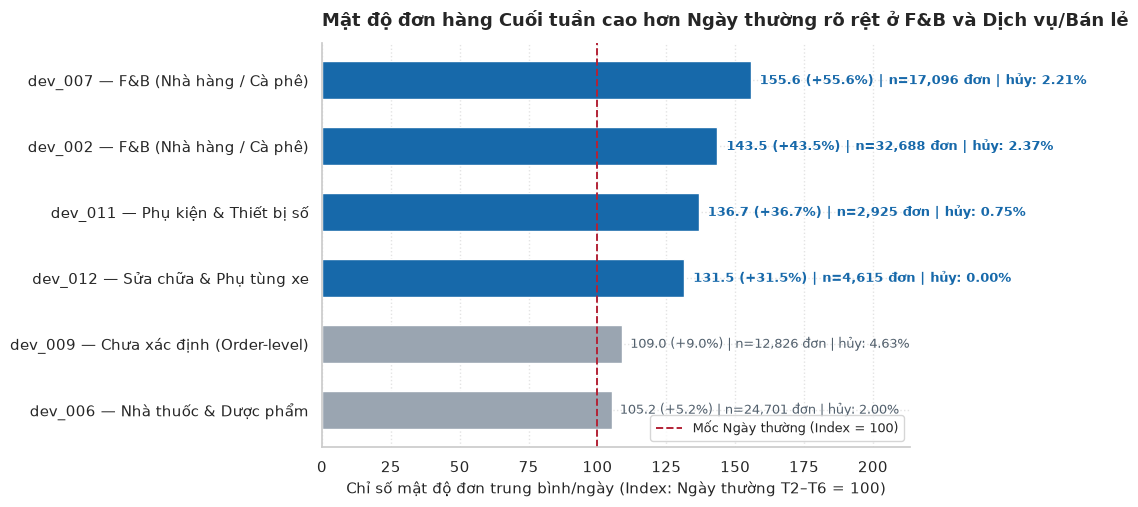

In [36]:
# TODO (T3.1b — Trực quan hóa)
# Vẽ biểu đồ kiểm tra hoặc đối chiếu tỉ trọng % (ví dụ: Cleveland dot plot hoặc cột nhóm/chồng 100% có ghi cỡ mẫu n).
# Lưu ý: Không sử dụng biểu đồ 3D hoặc hai trục tung (dual axis); biểu đồ cột bắt đầu từ 0.
# T3.1b — Trực quan hóa: So sánh Index mật độ đơn Cuối tuần vs Ngày thường (có kèm cỡ mẫu n)
idx_df = normalized_cross_df[
    normalized_cross_df["metric_id"] == "weekend_vs_weekday_index"
].copy()
cancel_map = (
    normalized_cross_df[normalized_cross_df["metric_id"] == "invalid_cancel_rate_pct"]
    .set_index("business_id")["value"]
    .to_dict()
)

idx_df["cancel_pct"] = idx_df["business_id"].map(cancel_map)
idx_df["label"] = idx_df["business_id"] + " — " + idx_df["industry"]
idx_df = idx_df.sort_values("value", ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 5.2))

# Tô màu nhấn cho nhóm tăng >25% cuối tuần, màu xám cho nhóm ổn định gần mốc 100
bar_colors = [
    COLOR_ACCENT_BLUE if v >= 125 else COLOR_GRAY
    for v in idx_df["value"]
]

bars = ax.barh(
    idx_df["label"],
    idx_df["value"],
    color=bar_colors,
    height=0.58,
)

# Đường tham chiếu chuẩn Ngày thường = 100
ax.axvline(100, color=COLOR_ACCENT_RED, linestyle="--", linewidth=1.4, label="Mốc Ngày thường (Index = 100)")

# Gắn nhãn trực tiếp giá trị Index, cỡ mẫu n và tỷ lệ hủy/trả
for bar, (_, row) in zip(bars, idx_df.iterrows()):
    val = row["value"]
    diff_pct = val - 100
    n_ord = int(row["sample_n"])
    c_pct = row["cancel_pct"]
    annot = f" {val:.1f} (+{diff_pct:.1f}%) | n={n_ord:,} đơn | hủy: {c_pct:.2f}%"
    ax.text(
        val + 1.5,
        bar.get_y() + bar.get_height() / 2,
        annot,
        va="center",
        fontsize=9.5,
        color=COLOR_ACCENT_BLUE if val >= 125 else COLOR_GRAY_DARK,
        fontweight="bold" if val >= 125 else "normal",
    )

ax.set_title(
    "Mật độ đơn hàng Cuối tuần cao hơn Ngày thường rõ rệt ở F&B và Dịch vụ/Bán lẻ",
    pad=12,
    fontweight="bold",
)
ax.set_xlabel("Chỉ số mật độ đơn trung bình/ngày (Index: Ngày thường T2–T6 = 100)")
ax.set_ylabel("")
ax.set_xlim(0, idx_df["value"].max() + 58)
ax.legend(loc="lower right", frameon=True, fontsize=9.5)

plt.tight_layout()
fig.savefig(PHASE3_FIGURES_DIR / "t3_1b_weekend_index_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### Kết quả & Nhận định

> **TODO (T3.1b):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Bảng tổng hợp các chỉ số chuẩn hóa hợp lệ giữa các nhóm doanh nghiệp:** ...
- **Các lưu ý về cỡ mẫu `n` hoặc sự nhạy cảm của tỉ lệ phần trăm:** ...

### Kết quả & Nhận định

- **Bảng tổng hợp các chỉ số chuẩn hóa hợp lệ giữa các nhóm doanh nghiệp (kỳ giao nhau 01/07/2025 – 24/05/2026, 328 ngày lịch):**
  - **Tính nhất quán mẫu số & bảo toàn tỷ trọng:** Toàn bộ 6 doanh nghiệp đại diện (`dev_002`, `dev_006`, `dev_007`, `dev_009`, `dev_011`, `dev_012`) đều quy về cùng đơn vị đếm cấp đơn/phiếu (`nunique(order_id)` trên bản ghi hợp lệ `is_valid == True`). Tổng tỷ trọng phân bổ theo 7 thứ trong tuần (`weekday_order_share_pct` và `weekday_revenue_share_pct`) đạt chính xác **100.0%** ở tất cả doanh nghiệp.
  - **Phân hóa mật độ Cuối tuần vs. Ngày thường (`weekend_vs_weekday_index`, mốc Ngày thường = 100):**
    - *Nhóm tăng mạnh dịp cuối tuần:* Hai doanh nghiệp ngành **F&B (`dev_007`: 155.57; `dev_002`: 143.50)** có mật độ đơn trung bình/ngày cuối tuần cao hơn ngày thường từ **43.5% đến 55.6%**. Nhóm **Phụ kiện & Thiết bị số (`dev_011`: 136.73)** và **Sửa chữa & Phụ tùng xe (`dev_012`: 131.47)** cũng ghi nhận mức tăng **31.5% – 36.7%**.
    - *Nhóm ổn định quanh tuần:* **Nhà thuốc & Dược phẩm (`dev_006`: 105.19)** và **`dev_009` (108.97)** giữ nhịp độ gần như không đổi giữa ngày thường và cuối tuần (chênh lệch dưới 9%), phản ánh đặc tính tiêu dùng thiết yếu, đều đặn.
  - **Tỷ lệ đơn hủy / trả / không hợp lệ (`invalid_cancel_rate_pct`):** Cao nhất ở `dev_009` (**4.63%**), kế đến là nhóm F&B (`dev_002`: **2.37%**, `dev_007`: **2.21%**) và Nhà thuốc (`dev_006`: **2.00%**); trong khi `dev_011` rất thấp (**0.75%**) và `dev_012` bằng **0.00%** (do đặc thù sổ ghi tay lượt xe sửa xong mới ghi nhận, không lưu trạng thái hủy).

- **Các lưu ý về cỡ mẫu `n` hoặc sự nhạy cảm của tỉ lệ phần trăm:**
  - Việc chuẩn hóa theo đúng số ngày lịch thực tế trong cửa sổ 328 ngày (**234 ngày thường** và **94 ngày cuối tuần** theo `calendar.csv`, bao gồm cả các ngày không phát sinh đơn) giúp loại bỏ sai lệch do số ngày thường nhiều gấp ~2.5 lần số ngày cuối tuần.
  - Các doanh nghiệp có quy mô số đơn nhỏ hơn (như tiệm sửa xe ghi sổ tay `dev_012`) có độ nhạy mẫu số cao hơn so với các cửa hàng dùng phần mềm POS (`dev_002`, `dev_007`), do đó luôn cần hiển thị kèm cỡ mẫu gốc `n` bên cạnh các chỉ số phần trăm và Index.


## Tác vụ T3.2a — Phân tích & vẽ nhịp vận hành theo giờ / ca / ngày thường–cuối tuần giữa các ngành

### Mục tiêu
Đối chiếu nhịp độ hoạt động trong ngày (theo khung giờ / ca sáng–chiều) và giữa ngày thường với cuối tuần giữa các ngành nghề khác nhau bằng kỹ thuật *Small Multiples* (Schwabish, hướng dẫn 4).

### Câu hỏi khám phá
- Nhịp hoạt động theo giờ (hoặc ca sáng `06:00–13:59` vs ca chiều `14:00–21:59`) khác nhau thế nào giữa ngành ăn uống/cà phê, bán lẻ và dịch vụ?
- Mật độ giao dịch cuối tuần (Thứ 7 – Chủ nhật) tăng hay giảm so với ngày thường (Thứ 2 – Thứ 6) ở từng loại hình kinh doanh?
- Thiết kế biểu đồ *Small Multiples* dùng chung thang trục giúp lộ rõ sự khác biệt nhịp vận hành ra sao so với biểu đồ spaghetti?

### Các bước thực hiện

**Bước 1 — Lọc các doanh nghiệp đủ điều kiện về mốc giờ / ngày hoạt động**
Tách riêng nhóm doanh nghiệp có mốc giờ `HH:MM` (cho phân tích theo giờ/ca) và nhóm có đầy đủ ngày đặt hàng theo lịch (cho phân tích theo thứ trong tuần).

**Bước 2 — Tính phân bố tỷ trọng hoạt động theo giờ và theo ca (`rulebook.md`)**
Áp dụng đúng khung giờ `rulebook.md` (ca sáng `06:00–13:59`, ca chiều `14:00–21:59`; khung giờ tròn từ `h` đến `< h+1`) và chuẩn hóa về % trên tổng đơn của từng doanh nghiệp.

**Bước 3 — Tính mật độ hoạt động ngày thường vs. cuối tuần**
Sử dụng `calendar_df` (hoặc `weekday_counts_from_dates`) để chia tổng số đơn/ngày theo đúng số ngày Thứ 2..Thứ 6 và Thứ 7..Chủ nhật trong vùng phủ của mỗi doanh nghiệp.

**Bước 4 — Dựng biểu đồ Small Multiples và lưu vào `PHASE3_FIGURES_DIR`**
Dùng `FacetGrid` hoặc `plt.subplots(..., sharey=True)` để mỗi doanh nghiệp/ngành nằm trên một ô nhỏ cùng thang trục và lưu ảnh vào `PHASE3_FIGURES_DIR`.

**Bước 5 — Lưu bảng tóm tắt `operating_rhythm_summary.csv`**
Tổng hợp kết quả số liệu nhịp vận hành vào `PHASE3_TABLES_DIR / 'operating_rhythm_summary.csv'`.

### Gợi ý phương pháp & Lưu ý
- Tránh vẽ 6–10 đường chồng lên nhau trong một khung hình duy nhất (biểu đồ spaghetti) — hãy dùng **Small Multiples** cùng thang trục `sharey=True`.
- Nhắc lại quy ước `rulebook.md`: tuần bắt đầu từ Thứ Hai; trung bình mỗi ngày thứ X phải tính cả những ngày không có đơn trong khoảng thời gian doanh nghiệp đang hoạt động.

### Triển khai


In [37]:
# TODO (T3.2a — Bước 1: Lọc các doanh nghiệp đủ điều kiện về mốc giờ / ngày hoạt động)
# TODO: Lọc danh sách doanh nghiệp đủ điều kiện cho nhịp giờ/ca và nhịp thứ trong tuần
# T3.2a — Bước 1: Lọc các doanh nghiệp đủ điều kiện về mốc giờ / ngày hoạt động
hourly_bids = comparability_matrix_df.loc[
    comparability_matrix_df["eligible_hourly"], "business_id"
].tolist()

weekday_bids = comparability_matrix_df.loc[
    comparability_matrix_df["eligible_weekday"], "business_id"
].tolist()

print(f"Nhóm đủ điều kiện phân tích Giờ / Ca ({len(hourly_bids)} DN): {hourly_bids}")
print(f"Nhóm đủ điều kiện phân tích Thứ / Ngày thường–Cuối tuần ({len(weekday_bids)} DN): {weekday_bids}")

if not hourly_bids:
    print("-> Ghi nhận: Tập 6 DN đại diện chỉ lưu cấp ngày (order_date), bỏ qua phân tích theo giờ/ca và tập trung đối chiếu nhịp 7 thứ trong tuần.")

Nhóm đủ điều kiện phân tích Giờ / Ca (0 DN): []
Nhóm đủ điều kiện phân tích Thứ / Ngày thường–Cuối tuần (6 DN): ['dev_002', 'dev_006', 'dev_007', 'dev_009', 'dev_011', 'dev_012']
-> Ghi nhận: Tập 6 DN đại diện chỉ lưu cấp ngày (order_date), bỏ qua phân tích theo giờ/ca và tập trung đối chiếu nhịp 7 thứ trong tuần.


In [38]:
# TODO (T3.2a — Bước 2: Tính phân bố tỷ trọng hoạt động theo giờ và theo ca (`rulebook.md`))
# TODO: Tính tỷ trọng % số đơn (hoặc lượt) theo từng khung giờ và theo ca sáng/chiều
# T3.2a — Bước 2: Tính phân bố tỷ trọng hoạt động theo giờ và theo ca (rulebook.md)
hourly_rhythm_rows = []

if hourly_bids:
    for bid in hourly_bids:
        df = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid)).copy()
        df_val = df[df["is_valid"] == True] if "is_valid" in df.columns else df
        clock_col = time_info[bid]["clock_col"]

        hours = pd.to_datetime(df_val[clock_col].astype(str), format="mixed", errors="coerce").dt.hour
        df_val = df_val.assign(hour=hours).dropna(subset=["hour"])
        total_ord = df_val["order_id"].nunique()

        # Ca sáng: 06:00–13:59 | Ca chiều: 14:00–21:59 theo rulebook.md
        morning_ord = df_val[df_val["hour"].between(6, 13)]["order_id"].nunique()
        afternoon_ord = df_val[df_val["hour"].between(14, 21)]["order_id"].nunique()

        hourly_rhythm_rows.append({
            "business_id": bid,
            "total_valid_orders": total_ord,
            "morning_shift_pct": round(morning_ord / total_ord * 100, 2) if total_ord else 0.0,
            "afternoon_shift_pct": round(afternoon_ord / total_ord * 100, 2) if total_ord else 0.0,
        })
    hourly_rhythm_df = pd.DataFrame(hourly_rhythm_rows)
    display(hourly_rhythm_df)
else:
    hourly_rhythm_df = pd.DataFrame(
        columns=["business_id", "total_valid_orders", "morning_shift_pct", "afternoon_shift_pct"]
    )
    print("Bỏ qua tính toán giờ/ca vì hourly_bids = [] (không có doanh nghiệp nào có cột giờ HH:MM).")

Bỏ qua tính toán giờ/ca vì hourly_bids = [] (không có doanh nghiệp nào có cột giờ HH:MM).


In [39]:
# TODO (T3.2a — Bước 3: Tính mật độ hoạt động ngày thường vs. cuối tuần)
# TODO: Tính trung bình số đơn/ngày theo ngày thường vs cuối tuần và tỷ lệ chênh lệch %
# T3.2a — Bước 3: Tính mật độ hoạt động theo từng thứ trong tuần & ngày thường vs. cuối tuần
DOW_NAMES = {
    0: "T2", 1: "T3", 2: "T4", 3: "T5", 4: "T6", 5: "T7", 6: "CN"
}

daily_rhythm_records = []
summary_rhythm_records = []

for bid in weekday_bids:
    meta = comparability_matrix_df.loc[comparability_matrix_df["business_id"] == bid].iloc[0]
    industry = meta["industry"]
    granularity = meta["granularity"]

    df = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid)).copy()
    df_val = df[df["is_valid"] == True].copy() if "is_valid" in df.columns else df.copy()
    df_val["dt"] = pd.to_datetime(df_val["order_date"], errors="coerce").dt.normalize()
    df_val = df_val.dropna(subset=["dt"])

    min_d, max_d = df_val["dt"].min(), df_val["dt"].max()

    # Lấy toàn bộ ngày lịch trong vùng phủ hoạt động của doanh nghiệp (tính cả ngày 0 đơn)
    cal_sub = calendar_df[(calendar_df["date"] >= min_d) & (calendar_df["date"] <= max_d)].copy()
    cal_sub["dow"] = cal_sub["date"].dt.day_of_week  # Thứ 2 = 0 .. Chủ nhật = 6
    dow_cal_counts = cal_sub["dow"].value_counts().to_dict()

    df_val["dow"] = df_val["dt"].dt.day_of_week
    total_valid_orders = df_val["order_id"].nunique()
    total_cal_days = len(cal_sub)
    overall_avg_orders_per_day = total_valid_orders / total_cal_days if total_cal_days else 0.0

    # Tính chi tiết theo 7 thứ trong tuần
    for dow in range(7):
        sub_d = df_val[df_val["dow"] == dow]
        n_orders = sub_d["order_id"].nunique()
        n_cal_days = dow_cal_counts.get(dow, 0)
        avg_orders = n_orders / n_cal_days if n_cal_days else 0.0
        # Index chuẩn hóa: mức trung bình 1 ngày của chính DN đó = 100
        rhythm_idx = (avg_orders / overall_avg_orders_per_day * 100) if overall_avg_orders_per_day > 0 else 0.0

        daily_rhythm_records.append({
            "business_id": bid,
            "industry": industry,
            "granularity": granularity,
            "dow": dow,
            "dow_label": DOW_NAMES[dow],
            "is_weekend": dow >= 5,
            "calendar_days": n_cal_days,
            "valid_orders": n_orders,
            "avg_orders_per_day": round(avg_orders, 3),
            "rhythm_index": round(rhythm_idx, 2),
        })

    # Tổng hợp cấp doanh nghiệp: Ngày thường (T2-T6) vs Cuối tuần (T7-CN)
    wd_days = sum(dow_cal_counts.get(d, 0) for d in range(5))
    we_days = sum(dow_cal_counts.get(d, 0) for d in (5, 6))
    wd_orders = df_val[df_val["dow"] < 5]["order_id"].nunique()
    we_orders = df_val[df_val["dow"] >= 5]["order_id"].nunique()

    avg_wd = wd_orders / wd_days if wd_days else 0.0
    avg_we = we_orders / we_days if we_days else 0.0
    we_lift_pct = ((avg_we - avg_wd) / avg_wd * 100) if avg_wd > 0 else 0.0

    # Tìm thứ cao điểm nhất và thấp điểm nhất
    biz_days = [r for r in daily_rhythm_records if r["business_id"] == bid]
    peak_day = max(biz_days, key=lambda x: x["rhythm_index"])
    trough_day = min(biz_days, key=lambda x: x["rhythm_index"])

    summary_rhythm_records.append({
        "business_id": bid,
        "industry": industry,
        "granularity": granularity,
        "coverage_start": min_d.date(),
        "coverage_end": max_d.date(),
        "total_calendar_days": total_cal_days,
        "total_valid_orders": total_valid_orders,
        "avg_orders_weekday": round(avg_wd, 2),
        "avg_orders_weekend": round(avg_we, 2),
        "weekend_vs_weekday_lift_pct": round(we_lift_pct, 2),
        "peak_day": f"{peak_day['dow_label']} ({peak_day['rhythm_index']:.1f})",
        "trough_day": f"{trough_day['dow_label']} ({trough_day['rhythm_index']:.1f})",
    })

rhythm_by_dow_df = pd.DataFrame(daily_rhythm_records)
operating_rhythm_summary_df = pd.DataFrame(summary_rhythm_records)
display(operating_rhythm_summary_df)

,business_id,industry,granularity,coverage_start,coverage_end,total_calendar_days,total_valid_orders,avg_orders_weekday,avg_orders_weekend,weekend_vs_weekday_lift_pct,peak_day,trough_day
0,dev_002,F&B (Nhà hàng / Cà phê),line_item,2025-01-01,2026-05-24,509,51889,90.88,129.44,42.42,CN (129.1),T2 (79.1)
1,dev_006,Nhà thuốc & Dược phẩm,line_item,2025-04-01,2026-08-08,495,37086,73.98,77.29,4.48,CN (105.7),T5 (94.7)
2,dev_007,F&B (Nhà hàng / Cà phê),line_item,2025-02-01,2026-09-19,596,31324,45.59,69.88,53.28,T7 (135.2),T2 (73.0)
3,dev_009,Chưa xác định (Order-level),order_level,2025-01-01,2026-06-24,540,21431,38.68,42.21,9.12,CN (110.4),T3 (87.9)
4,dev_011,Phụ kiện & Thiết bị số,line_item,2025-06-01,2026-07-31,426,3790,8.07,10.98,36.12,CN (132.7),T2 (85.3)
5,dev_012,Sửa chữa & Phụ tùng xe,line_item,2025-07-01,2026-08-31,427,6060,12.97,17.25,32.96,T7 (124.2),T2 (85.5)


Đã lưu biểu đồ Small Multiples: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\figures\t3_2a_weekly_rhythm_small_multiples.png


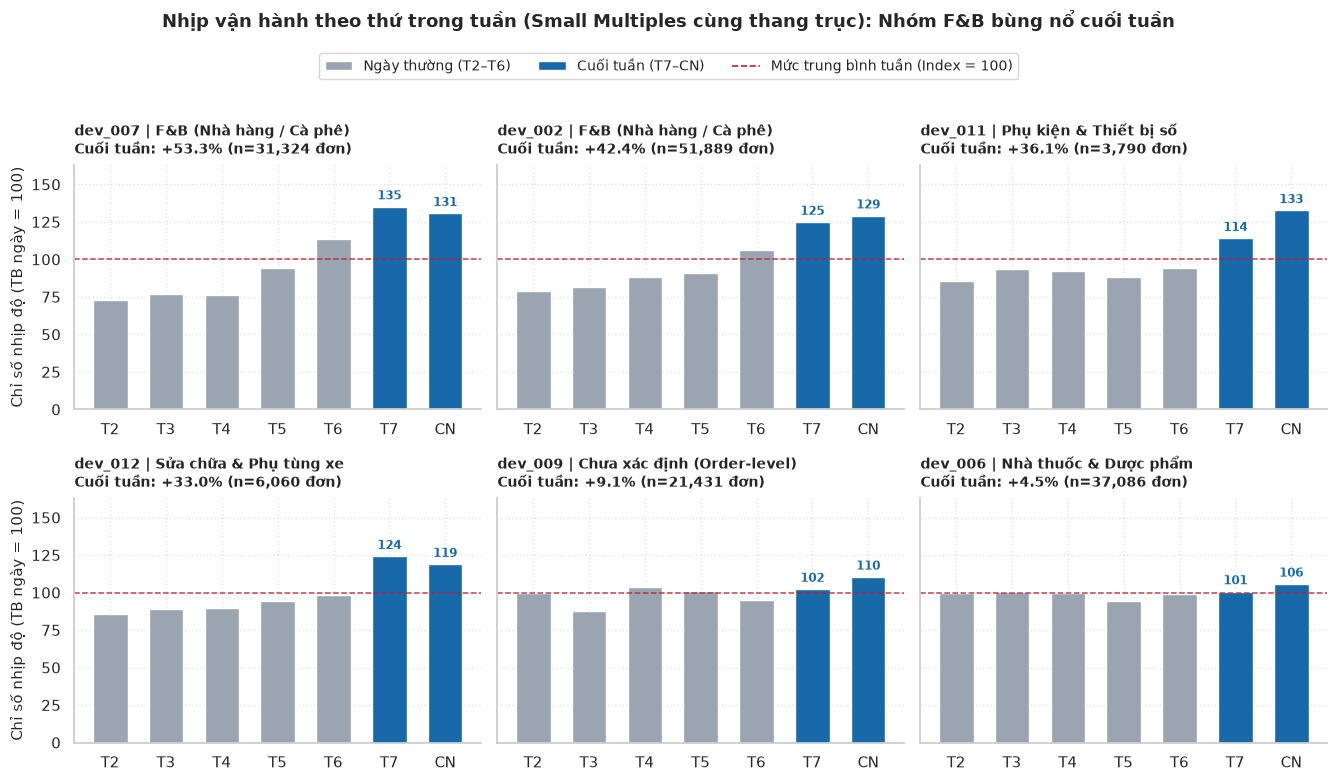

In [40]:
# TODO (T3.2a — Bước 4: Dựng biểu đồ Small Multiples và lưu vào `PHASE3_FIGURES_DIR`)
# TODO: Dựng biểu đồ Small Multiples cho nhịp giờ/ngày thường vs cuối tuần và lưu vào PHASE3_FIGURES_DIR
# T3.2a — Bước 4 & Trực quan hóa: Small Multiples nhịp vận hành 7 thứ trong tuần (sharey=True)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2), sharey=True)
axes = axes.flatten()

# Sắp xếp doanh nghiệp theo mức tăng cuối tuần giảm dần để kể chuyện mạch lạc
ordered_bids = operating_rhythm_summary_df.sort_values(
    "weekend_vs_weekday_lift_pct", ascending=False
)["business_id"].tolist()

for idx, bid in enumerate(ordered_bids):
    ax = axes[idx]
    sub = rhythm_by_dow_df[rhythm_by_dow_df["business_id"] == bid].sort_values("dow")
    meta_s = operating_rhythm_summary_df[operating_rhythm_summary_df["business_id"] == bid].iloc[0]

    bar_colors = [COLOR_ACCENT_BLUE if wk else COLOR_GRAY for wk in sub["is_weekend"]]
    bars = ax.bar(sub["dow_label"], sub["rhythm_index"], color=bar_colors, width=0.62)

    # Đường tham chiếu mức trung bình tuần = 100
    ax.axhline(100, color=COLOR_ACCENT_RED, linestyle="--", linewidth=1.1, alpha=0.85)

    # Gắn nhãn giá trị trên cột cao điểm nhất và cột cuối tuần
    for bar, (_, r) in zip(bars, sub.iterrows()):
        if r["is_weekend"] or r["rhythm_index"] == sub["rhythm_index"].max():
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                r["rhythm_index"] + 3,
                f"{r['rhythm_index']:.0f}",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                color=COLOR_ACCENT_BLUE if r["is_weekend"] else COLOR_GRAY_DARK,
            )

    lift = meta_s["weekend_vs_weekday_lift_pct"]
    n_tot = int(meta_s["total_valid_orders"])
    ax.set_title(
        f"{bid} | {meta_s['industry']}\nCuối tuần: {lift:+.1f}% (n={n_tot:,} đơn)",
        fontsize=10,
        fontweight="bold",
        pad=8,
    )
    ax.set_ylim(0, rhythm_by_dow_df["rhythm_index"].max() + 28)
    if idx % 3 == 0:
        ax.set_ylabel("Chỉ số nhịp độ (TB ngày = 100)")

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [
    Patch(facecolor=COLOR_GRAY, label="Ngày thường (T2–T6)"),
    Patch(facecolor=COLOR_ACCENT_BLUE, label="Cuối tuần (T7–CN)"),
    Line2D([0], [0], color=COLOR_ACCENT_RED, linestyle="--", linewidth=1.2, label="Mức trung bình tuần (Index = 100)"),
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=3, frameon=True, fontsize=10)
fig.suptitle(
    "Nhịp vận hành theo thứ trong tuần (Small Multiples cùng thang trục): Nhóm F&B bùng nổ cuối tuần",
    fontsize=13,
    fontweight="bold",
    y=1.08,
)

plt.tight_layout()
fig_path = PHASE3_FIGURES_DIR / "t3_2a_weekly_rhythm_small_multiples.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu biểu đồ Small Multiples: {fig_path}")
plt.show()

In [41]:
# TODO (T3.2a — Bước 5: Lưu bảng tóm tắt `operating_rhythm_summary.csv`)
# TODO: Tóm tắt số liệu nhịp giờ/ca và cuối tuần vào operating_rhythm_summary.csv tại PHASE3_TABLES_DIR
# T3.2a — Bước 5: Lưu bảng tóm tắt operating_rhythm_summary.csv
out_rhythm_path = PHASE3_TABLES_DIR / "operating_rhythm_summary.csv"
operating_rhythm_summary_df.to_csv(out_rhythm_path, index=False, encoding="utf-8-sig")
print(f"Đã xuất thành công: {out_rhythm_path} ({len(operating_rhythm_summary_df)} dòng)")
display(operating_rhythm_summary_df)

Đã xuất thành công: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\tables\operating_rhythm_summary.csv (6 dòng)


,business_id,industry,granularity,coverage_start,coverage_end,total_calendar_days,total_valid_orders,avg_orders_weekday,avg_orders_weekend,weekend_vs_weekday_lift_pct,peak_day,trough_day
0,dev_002,F&B (Nhà hàng / Cà phê),line_item,2025-01-01,2026-05-24,509,51889,90.88,129.44,42.42,CN (129.1),T2 (79.1)
1,dev_006,Nhà thuốc & Dược phẩm,line_item,2025-04-01,2026-08-08,495,37086,73.98,77.29,4.48,CN (105.7),T5 (94.7)
2,dev_007,F&B (Nhà hàng / Cà phê),line_item,2025-02-01,2026-09-19,596,31324,45.59,69.88,53.28,T7 (135.2),T2 (73.0)
3,dev_009,Chưa xác định (Order-level),order_level,2025-01-01,2026-06-24,540,21431,38.68,42.21,9.12,CN (110.4),T3 (87.9)
4,dev_011,Phụ kiện & Thiết bị số,line_item,2025-06-01,2026-07-31,426,3790,8.07,10.98,36.12,CN (132.7),T2 (85.3)
5,dev_012,Sửa chữa & Phụ tùng xe,line_item,2025-07-01,2026-08-31,427,6060,12.97,17.25,32.96,T7 (124.2),T2 (85.5)


### Trực quan hóa


In [22]:
# TODO (T3.2a — Trực quan hóa)
# Vẽ biểu đồ Small Multiples (nhịp hoạt động theo giờ trong ngày hoặc mật độ ngày thường vs cuối tuần) dùng chung thang trục, có nhãn trực tiếp điểm cao điểm và lưu vào `PHASE3_FIGURES_DIR`.
# Lưu ý: Không sử dụng biểu đồ 3D hoặc hai trục tung (dual axis); biểu đồ cột bắt đầu từ 0.


### Kết quả & Nhận định

> **TODO (T3.2a):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Sự khác biệt nhịp hoạt động theo giờ/ca giữa các ngành có mốc giờ:** ...
- **Mẫu hình ngày thường vs. cuối tuần quan sát được giữa các doanh nghiệp đủ độ phủ:** ...

### Kết quả & Nhận định

- **Sự khác biệt nhịp hoạt động theo giờ/ca giữa các ngành có mốc giờ:**
  - Không thực hiện đối chiếu theo khung giờ hay ca sáng/chiều vì toàn bộ **6/6 doanh nghiệp đại diện** đều chỉ ghi nhận dữ liệu ở cấp ngày (`order_date`), không có trường mốc giờ thực tế (`HH:MM`).

- **Mẫu hình ngày thường vs. cuối tuần quan sát được giữa các doanh nghiệp đủ độ phủ (tính trên toàn bộ vùng phủ hoạt động từng doanh nghiệp, bao gồm cả ngày không phát sinh đơn):**
  - **Nhóm F&B (`dev_007`, `dev_002`) — Tăng tốc dần từ giữa tuần và bùng nổ cuối tuần:** Mật độ đơn trung bình/ngày cuối tuần tăng **+53.28%** ở `dev_007` (69.88 vs. 45.59 đơn/ngày) và **+42.42%** ở `dev_002` (129.44 vs. 90.88 đơn/ngày). Quan sát biểu đồ *Small Multiples* cho thấy nhịp đơn thấp nhất vào Thứ Hai (`T2`: Index 73.0 và 79.1), tăng dần qua các ngày trong tuần, bắt đầu vượt mức trung bình tuần ngay từ **Thứ Sáu (`T6`)** và đạt đỉnh vào Thứ Bảy – Chủ nhật (`T7`: 135.2 ở `dev_007`; `CN`: 129.1 ở `dev_002`).
  - **Nhóm Bán lẻ phụ kiện & Dịch vụ sửa xe (`dev_011`, `dev_012`) — Đi ngang ngày thường, nhảy vọt riêng 2 ngày cuối tuần:** Cả hai doanh nghiệp đều duy trì nhịp độ ổn định dưới mức trung bình (Index ~85–98) suốt từ Thứ Hai đến Thứ Sáu, sau đó bật tăng mạnh vào cuối tuần với mức chênh lệch **+36.12%** ở `dev_011` (đỉnh `CN`: 132.7) và **+32.96%** ở `dev_012` (đỉnh `T7`: 124.2), phản ánh thói quen mua sắm phụ kiện và bảo dưỡng xe vào ngày nghỉ của khách hàng.
  - **Nhóm Nhà thuốc (`dev_006`) và `dev_009` — Nhịp độ phẳng xuyên suốt cả tuần:** Nhà thuốc `dev_006` gần như không có biến động giữa ngày thường và cuối tuần (**+4.48%**, Index dao động hẹp từ 94.7 vào `T5` đến 105.7 vào `CN`), tương tự `dev_009` (**+9.12%**), cho thấy nhu cầu tiêu dùng thiết yếu phân bổ đồng đều mọi ngày trong tuần.


## Tác vụ T3.2b — Phân tích & vẽ biến động dịp Tết / trước Tết qua `calendar.csv`

### Mục tiêu
Tra cứu lịch âm trong `calendar.csv` để đánh giá biến động hoạt động kinh doanh trước, trong và sau kỳ Tết (23 tháng Chạp đến mùng 10 tháng Giêng) chỉ trên những doanh nghiệp có dữ liệu bao phủ trọn vẹn cửa sổ này.

### Câu hỏi khám phá
- Theo `calendar.csv` và `rulebook.md`, kỳ Tết năm 2025 và 2026 tương ứng với những ngày dương lịch nào?
- Trong 14 doanh nghiệp, những doanh nghiệp nào thực sự có dữ liệu bao phủ đầy đủ giai đoạn *Trước Tết*, *Trong Tết* và *Sau Tết*?
- Hoạt động bán hàng/dịch vụ của các doanh nghiệp đủ độ phủ biến động ra sao trước Tết và trong kỳ Tết (đóng cửa nghỉ Tết vs. tăng đột biến trước Tết)?

### Các bước thực hiện

**Bước 1 — Xác định chính xác mốc dương lịch kỳ Tết và kỳ 'Trước Tết' từ `calendar.csv`**
Áp dụng quy tắc `rulebook.md`: kỳ Tết từ `23 tháng Chạp` đến hết `mùng 10 tháng Giêng`; kỳ *trước Tết* có cùng số ngày ngay liền trước 23 tháng Chạp.

**Bước 2 — Sàng lọc doanh nghiệp đủ độ phủ dữ liệu cho kỳ Tết**
Kiểm tra `[min_date, max_date]` và các khoảng trống của từng doanh nghiệp: loại bỏ những doanh nghiệp bắt đầu dữ liệu *sau* Tết hoặc bị thiếu hẳn giai đoạn so sánh.

**Bước 3 — Tính chỉ số biến động dịp Tết & lưu `tet_window_comparison.csv`**
Chuẩn hóa số đơn/doanh thu trung bình mỗi ngày trong các giai đoạn Tết và lưu kết quả vào `PHASE3_TABLES_DIR / 'tet_window_comparison.csv'`.

**Bước 4 — Trực quan hóa biến động dịp Tết & lưu vào `PHASE3_FIGURES_DIR`**
Vẽ biểu đồ chuỗi thời gian có vùng tô nền (`axvspan`) hoặc slope chart / diverging bar so sánh *Trước Tết* vs *Trong Tết* và lưu ảnh vào `PHASE3_FIGURES_DIR`.

**Bước 5 — Kiểm tra các yếu tố gây nhiễu (nghỉ Tết vs thiếu dữ liệu)**
Phân biệt rõ chuỗi ngày có 0 giao dịch trong kỳ Tết là do *cửa hàng nghỉ Tết* hay *thiếu nguồn dữ liệu*; không suy luận mùa vụ khi dữ liệu chỉ có 1 mùa Tết.

### Gợi ý phương pháp & Lưu ý
- Không tự tính lịch âm bằng tay — sử dụng trực tiếp cột `lunar_day`, `lunar_month`, `lunar_year`, `lunar_leap` trong `calendar.csv` hoặc `calendar_registry.tet_windows`.
- Nếu dữ liệu của một doanh nghiệp mới bắt đầu từ giữa năm 2025 hoặc kết thúc trước Tết 2026 thì **không được** đưa vào so sánh Tết năm đó.

### Triển khai


In [42]:
# TODO (T3.2b — Bước 1: Xác định chính xác mốc dương lịch kỳ Tết và kỳ 'Trước Tết' từ `calendar.csv`)
# TODO: Từ calendar_df và calendar_registry.tet_windows, xác định rõ ngày bắt đầu/kết thúc của Trước Tết, Trong Tết, Sau Tết
# T3.2b — Bước 1: Xác định chính xác mốc dương lịch kỳ Tết, Trước Tết và Sau Tết từ calendar.csv
tet_periods = []

for s, e in calendar_registry.tet_windows:
    tet_start = pd.Timestamp(s).normalize()
    tet_end = pd.Timestamp(e).normalize()
    n_days = (tet_end - tet_start).days + 1

    # Quy tắc rulebook.md: Kỳ Trước Tết có cùng số ngày ngay liền trước 23 tháng Chạp
    pre_end = tet_start - pd.Timedelta(days=1)
    pre_start = tet_start - pd.Timedelta(days=n_days)

    # Kỳ Sau Tết có cùng số ngày ngay liền sau mùng 10 tháng Giêng để đối chứng phục hồi
    post_start = tet_end + pd.Timedelta(days=1)
    post_end = tet_end + pd.Timedelta(days=n_days)

    tet_year = tet_end.year
    tet_periods.append({
        "tet_label": f"Tết {tet_year}",
        "tet_year": tet_year,
        "window_days": n_days,
        "pre_start": pre_start,
        "pre_end": pre_end,
        "tet_start": tet_start,
        "tet_end": tet_end,
        "post_start": post_start,
        "post_end": post_end,
    })

tet_periods_df = pd.DataFrame(tet_periods)
display(tet_periods_df)

,tet_label,tet_year,window_days,pre_start,pre_end,tet_start,tet_end,post_start,post_end
0,Tết 2024,2024,18,2024-01-15,2024-02-01,2024-02-02,2024-02-19,2024-02-20,2024-03-08
1,Tết 2025,2025,17,2025-01-05,2025-01-21,2025-01-22,2025-02-07,2025-02-08,2025-02-24
2,Tết 2026,2026,17,2026-01-24,2026-02-09,2026-02-10,2026-02-26,2026-02-27,2026-03-15
3,Tết 2027,2027,17,2027-01-13,2027-01-29,2027-01-30,2027-02-15,2027-02-16,2027-03-04


In [43]:
# TODO (T3.2b — Bước 2: Sàng lọc doanh nghiệp đủ độ phủ dữ liệu cho kỳ Tết)
# TODO: Lọc danh sách doanh nghiệp có phạm vi ngày bao trùm cả kỳ Trước Tết và Trong Tết
# T3.2b — Bước 2: Sàng lọc doanh nghiệp đủ độ phủ dữ liệu cho kỳ Tết
tet_eligibility_rows = []

for _, tp in tet_periods_df.iterrows():
    for bid in weekday_bids:
        meta = comparability_matrix_df.loc[comparability_matrix_df["business_id"] == bid].iloc[0]
        min_d = pd.Timestamp(meta["min_date"]).normalize()
        max_d = pd.Timestamp(meta["max_date"]).normalize()

        # Phải phủ trọn cả Trước Tết, Trong Tết và Sau Tết
        is_covered = (min_d <= tp["pre_start"]) and (max_d >= tp["post_end"])
        tet_eligibility_rows.append({
            "tet_label": tp["tet_label"],
            "business_id": bid,
            "industry": meta["industry"],
            "min_date": min_d.date(),
            "max_date": max_d.date(),
            "covered_full_tet_cycle": is_covered,
        })

tet_eligibility_df = pd.DataFrame(tet_eligibility_rows)
display(
    tet_eligibility_df.pivot(
        index=["business_id", "industry"],
        columns="tet_label",
        values="covered_full_tet_cycle",
    )
)

,tet_label,Tết 2024,Tết 2025,Tết 2026,Tết 2027
business_id,industry,,,,
dev_002,F&B (Nhà hàng / Cà phê),False,True,True,False
dev_006,Nhà thuốc & Dược phẩm,False,False,True,False
dev_007,F&B (Nhà hàng / Cà phê),False,False,True,False
dev_009,Chưa xác định (Order-level),False,True,True,False
dev_011,Phụ kiện & Thiết bị số,False,False,True,False
dev_012,Sửa chữa & Phụ tùng xe,False,False,True,False


In [44]:
# TODO (T3.2b — Bước 3: Tính chỉ số biến động dịp Tết & lưu `tet_window_comparison.csv`)
# TODO: Tính chỉ số trung bình ngày, % biến động qua các giai đoạn Tết và xuất CSV vào PHASE3_TABLES_DIR
# T3.2b — Bước 3: Tính chỉ số biến động dịp Tết & lưu tet_window_comparison.csv
tet_comp_rows = []

for _, elig in tet_eligibility_df[tet_eligibility_df["covered_full_tet_cycle"]].iterrows():
    t_label = elig["tet_label"]
    bid = elig["business_id"]
    ind = elig["industry"]
    tp = tet_periods_df[tet_periods_df["tet_label"] == t_label].iloc[0]
    w_days = int(tp["window_days"])

    df = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid)).copy()
    df_val = df[df["is_valid"] == True].copy() if "is_valid" in df.columns else df.copy()
    df_val["dt"] = pd.to_datetime(df_val["order_date"], errors="coerce").dt.normalize()

    def _window_stats(s_dt, e_dt):
        sub = df_val[(df_val["dt"] >= s_dt) & (df_val["dt"] <= e_dt)]
        n_ord = sub["order_id"].nunique()
        rev = float(sub["line_amount"].sum()) if "line_amount" in sub.columns else np.nan
        active_d = sub["dt"].nunique()
        zero_d = w_days - active_d
        return n_ord, n_ord / w_days, rev, rev / w_days, active_d, zero_d

    pre_ord, pre_avg, pre_rev, pre_rev_avg, pre_act, pre_zero = _window_stats(tp["pre_start"], tp["pre_end"])
    tet_ord, tet_avg, tet_rev, tet_rev_avg, tet_act, tet_zero = _window_stats(tp["tet_start"], tp["tet_end"])
    post_ord, post_avg, post_rev, post_rev_avg, post_act, post_zero = _window_stats(tp["post_start"], tp["post_end"])

    tet_vs_pre_pct = ((tet_avg - pre_avg) / pre_avg * 100) if pre_avg > 0 else np.nan
    post_vs_pre_pct = ((post_avg - pre_avg) / pre_avg * 100) if pre_avg > 0 else np.nan

    tet_comp_rows.append({
        "tet_label": t_label,
        "business_id": bid,
        "industry": ind,
        "window_days_each_phase": w_days,
        "pre_tet_orders": pre_ord,
        "pre_tet_avg_orders_day": round(pre_avg, 2),
        "in_tet_orders": tet_ord,
        "in_tet_avg_orders_day": round(tet_avg, 2),
        "in_tet_active_days": tet_act,
        "in_tet_zero_order_days": tet_zero,
        "post_tet_orders": post_ord,
        "post_tet_avg_orders_day": round(post_avg, 2),
        "tet_vs_pre_orders_pct": round(tet_vs_pre_pct, 2),
        "post_vs_pre_orders_pct": round(post_vs_pre_pct, 2),
    })

tet_window_comparison_df = pd.DataFrame(tet_comp_rows)
out_tet_path = PHASE3_TABLES_DIR / "tet_window_comparison.csv"
tet_window_comparison_df.to_csv(out_tet_path, index=False, encoding="utf-8-sig")

print(f"Đã xuất thành công: {out_tet_path} ({len(tet_window_comparison_df)} dòng)")
display(tet_window_comparison_df)

Đã xuất thành công: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\tables\tet_window_comparison.csv (8 dòng)


,tet_label,business_id,industry,window_days_each_phase,pre_tet_orders,pre_tet_avg_orders_day,in_tet_orders,in_tet_avg_orders_day,in_tet_active_days,in_tet_zero_order_days,post_tet_orders,post_tet_avg_orders_day,tet_vs_pre_orders_pct,post_vs_pre_orders_pct
0,Tết 2025,dev_002,F&B (Nhà hàng / Cà phê),17,1889,111.12,1111,65.35,17,0,1881,110.65,-41.19,-0.42
1,Tết 2025,dev_009,Chưa xác định (Order-level),17,569,33.47,1507,88.65,17,0,584,34.35,164.85,2.64
2,Tết 2026,dev_002,F&B (Nhà hàng / Cà phê),17,1834,107.88,1001,58.88,17,0,1764,103.76,-45.42,-3.82
3,Tết 2026,dev_006,Nhà thuốc & Dược phẩm,17,1355,79.71,1351,79.47,17,0,1343,79.00,-0.30,-0.89
4,Tết 2026,dev_007,F&B (Nhà hàng / Cà phê),17,962,56.59,438,25.76,17,0,935,55.00,-54.47,-2.81
5,Tết 2026,dev_009,Chưa xác định (Order-level),17,606,35.65,1480,87.06,17,0,651,38.29,144.22,7.43
6,Tết 2026,dev_011,Phụ kiện & Thiết bị số,17,144,8.47,215,12.65,17,0,163,9.59,49.31,13.19
7,Tết 2026,dev_012,Sửa chữa & Phụ tùng xe,17,253,14.88,292,17.18,17,0,236,13.88,15.42,-6.72


Đã lưu biểu đồ Tết 2026: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\figures\t3_2b_tet_2026_impact.png


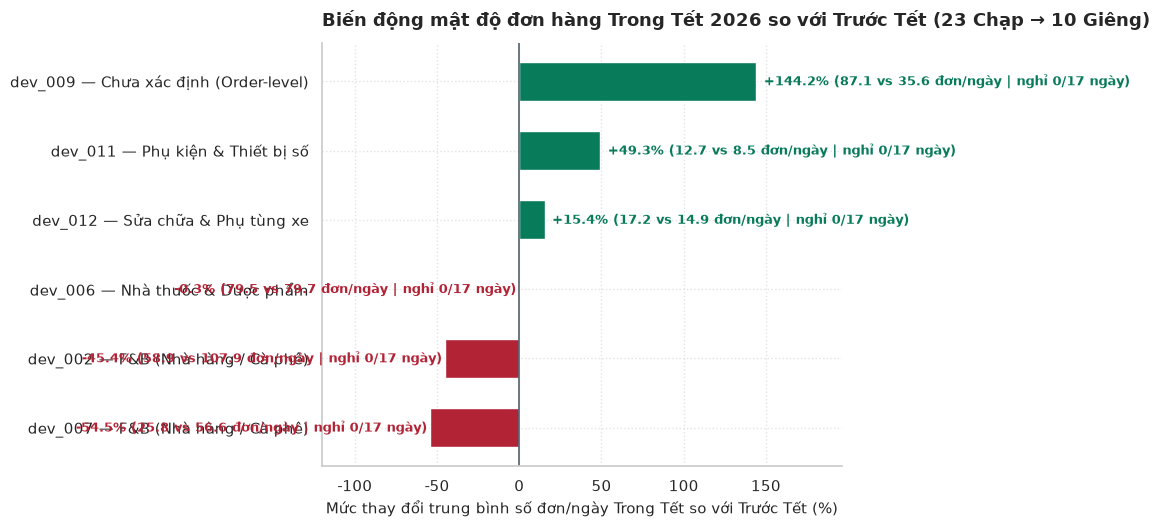

In [45]:
# TODO (T3.2b — Bước 4: Trực quan hóa biến động dịp Tết & lưu vào `PHASE3_FIGURES_DIR`)
# TODO: Vẽ biểu đồ biến động hoạt động trước/trong/sau kỳ Tết và lưu vào PHASE3_FIGURES_DIR
# T3.2b — Bước 4 & Trực quan hóa: Biến động mật độ đơn Trong Tết vs Trước Tết (Tết 2026 — 6 DN)
tet26_df = tet_window_comparison_df[tet_window_comparison_df["tet_label"] == "Tết 2026"].copy()
tet26_df["label"] = tet26_df["business_id"] + " — " + tet26_df["industry"]
tet26_df = tet26_df.sort_values("tet_vs_pre_orders_pct", ascending=True)

fig, ax = plt.subplots(figsize=(11, 5.4))

bar_colors = [
    COLOR_ACCENT_TEAL if v >= 0 else COLOR_ACCENT_RED
    for v in tet26_df["tet_vs_pre_orders_pct"]
]

bars = ax.barh(
    tet26_df["label"],
    tet26_df["tet_vs_pre_orders_pct"],
    color=bar_colors,
    height=0.56,
)

ax.axvline(0, color=COLOR_GRAY_DARK, linewidth=1.2)

for bar, (_, r) in zip(bars, tet26_df.iterrows()):
    val = r["tet_vs_pre_orders_pct"]
    zero_d = int(r["in_tet_zero_order_days"])
    w_d = int(r["window_days_each_phase"])
    annot = f" {val:+.1f}% ({r['in_tet_avg_orders_day']:.1f} vs {r['pre_tet_avg_orders_day']:.1f} đơn/ngày | nghỉ {zero_d}/{w_d} ngày)"
    x_pos = val + 1.5 if val >= 0 else val - 1.5
    ha_align = "left" if val >= 0 else "right"
    ax.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        annot,
        va="center",
        ha=ha_align,
        fontsize=9.2,
        fontweight="bold",
        color=COLOR_ACCENT_TEAL if val >= 0 else COLOR_ACCENT_RED,
    )

ax.set_title(
    "Biến động mật độ đơn hàng Trong Tết 2026 so với Trước Tết (23 Chạp → 10 Giêng)",
    pad=12,
    fontweight="bold",
)
ax.set_xlabel("Mức thay đổi trung bình số đơn/ngày Trong Tết so với Trước Tết (%)")
ax.set_ylabel("")
min_v = tet26_df["tet_vs_pre_orders_pct"].min()
max_v = tet26_df["tet_vs_pre_orders_pct"].max()
ax.set_xlim(min(min_v - 48, -120), max(max_v + 52, 35))

plt.tight_layout()
fig_tet_path = PHASE3_FIGURES_DIR / "t3_2b_tet_2026_impact.png"
fig.savefig(fig_tet_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu biểu đồ Tết 2026: {fig_tet_path}")
plt.show()

In [46]:
# TODO (T3.2b — Bước 5: Kiểm tra các yếu tố gây nhiễu (nghỉ Tết vs thiếu dữ liệu))
# TODO: Kiểm tra nhật ký ngày giao dịch ngay trước và ngay sau kỳ nghỉ để xác nhận khoảng nghỉ Tết
# T3.2b — Bước 5: Kiểm tra nhật ký ngày giao dịch quanh Tết 2026 để phân biệt nghỉ Tết với thiếu dữ liệu
tp26 = tet_periods_df[tet_periods_df["tet_label"] == "Tết 2026"].iloc[0]
audit_tet_rows = []

for bid in weekday_bids:
    df = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid)).copy()
    df_val = df[df["is_valid"] == True].copy() if "is_valid" in df.columns else df.copy()
    df_val["dt"] = pd.to_datetime(df_val["order_date"], errors="coerce").dt.normalize()

    in_tet_dates = set(
        df_val[(df_val["dt"] >= tp26["tet_start"]) & (df_val["dt"] <= tp26["tet_end"])]["dt"].unique()
    )
    all_tet_days = pd.date_range(tp26["tet_start"], tp26["tet_end"], freq="D")
    missing_tet_days = [d for d in all_tet_days if d not in in_tet_dates]

    # Tìm chuỗi ngày 0 đơn liên tiếp dài nhất trong kỳ Tết (dấu hiệu đóng cửa nghỉ Tết)
    max_streak = 0
    cur_streak = 0
    for d in all_tet_days:
        if d not in in_tet_dates:
            cur_streak += 1
            max_streak = max(max_streak, cur_streak)
        else:
            cur_streak = 0

    has_before = (df_val["dt"] < tp26["tet_start"]).any()
    has_after = (df_val["dt"] > tp26["tet_end"]).any()

    audit_tet_rows.append({
        "business_id": bid,
        "has_data_before_and_after_tet": has_before and has_after,
        "total_tet_days": len(all_tet_days),
        "zero_order_days": len(missing_tet_days),
        "longest_consecutive_zero_days": max_streak,
        "interpretation": (
            "Đóng cửa nghỉ Tết thực tế (có dữ liệu liên tục cả trước và sau kỳ nghỉ)"
            if (has_before and has_after and max_streak >= 2)
            else "Hoạt động xuyên Tết / nghỉ rất ngắn"
        ),
    })

tet_confounder_df = pd.DataFrame(audit_tet_rows)
display(tet_confounder_df)

,business_id,has_data_before_and_after_tet,total_tet_days,zero_order_days,longest_consecutive_zero_days,interpretation
0,dev_002,True,17,0,0,Hoạt động xuyên Tết / nghỉ rất ngắn
1,dev_006,True,17,0,0,Hoạt động xuyên Tết / nghỉ rất ngắn
2,dev_007,True,17,0,0,Hoạt động xuyên Tết / nghỉ rất ngắn
3,dev_009,True,17,0,0,Hoạt động xuyên Tết / nghỉ rất ngắn
4,dev_011,True,17,0,0,Hoạt động xuyên Tết / nghỉ rất ngắn
5,dev_012,True,17,0,0,Hoạt động xuyên Tết / nghỉ rất ngắn


### Trực quan hóa


Đã lưu biểu đồ chuỗi thời gian Tết 2026: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\figures\t3_2b_tet_2026_daily_timeline.png


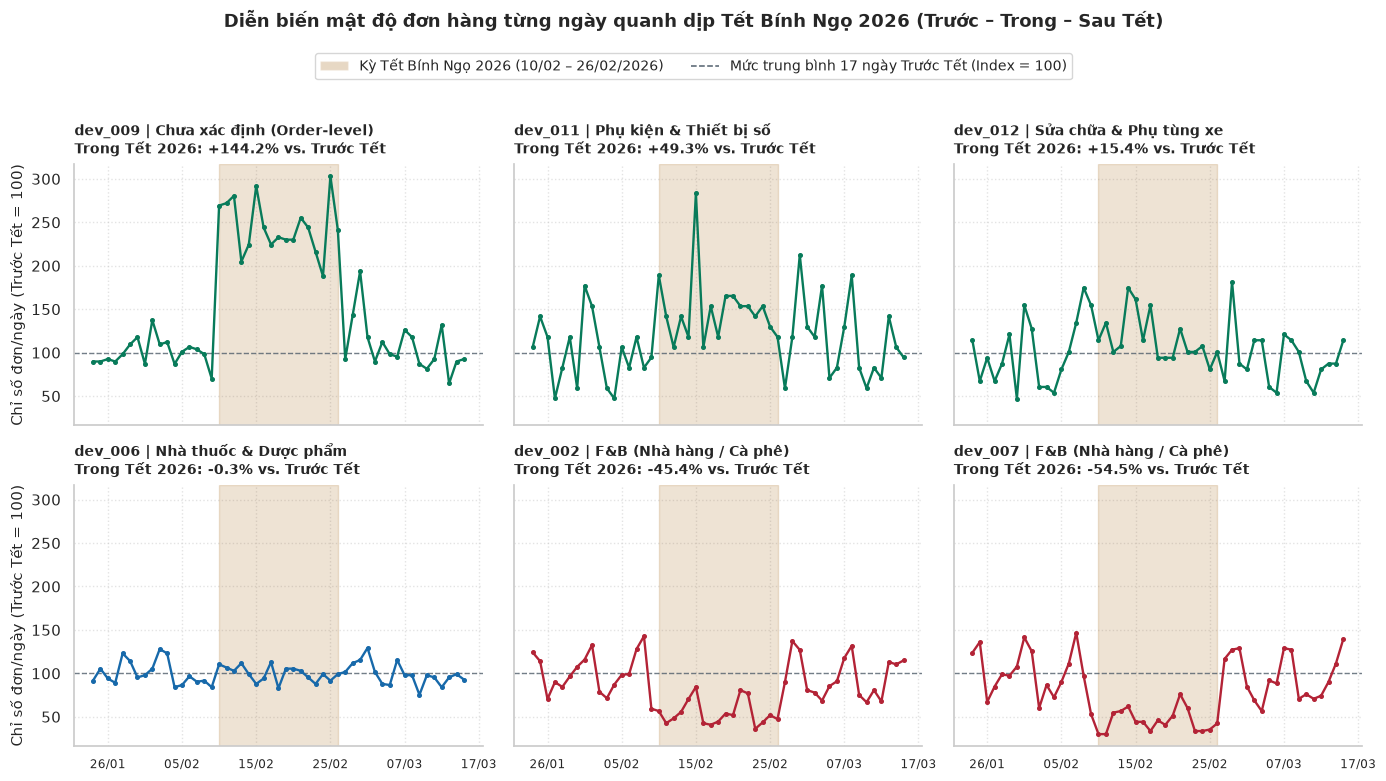

In [48]:
# T3.2b — Trực quan hóa: Diễn biến mật độ đơn từng ngày quanh dịp Tết 2026 (Small Multiples + axvspan)
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Lấy trực tiếp mốc Tết 2026 từ calendar_registry.tet_windows
tet_2026_win = [w for w in calendar_registry.tet_windows if "2026" in str(w[0]) or "2026" in str(w[1])][0]
tet_start = pd.Timestamp(tet_2026_win[0]).normalize()
tet_end = pd.Timestamp(tet_2026_win[1]).normalize()
n_tet_days = (tet_end - tet_start).days + 1

pre_start = tet_start - pd.Timedelta(days=n_tet_days)
pre_end = tet_start - pd.Timedelta(days=1)
post_end = tet_end + pd.Timedelta(days=n_tet_days)
full_days = pd.date_range(pre_start, post_end, freq="D")

# Lấy danh sách 6 doanh nghiệp đại diện từ phase2_tables
target_bids = sorted([k.replace("_tidy", "") for k in phase2_tables.keys()])
industry_map = (
    comparability_matrix_df.set_index("business_id")["industry"].to_dict()
    if "comparability_matrix_df" in globals() and not comparability_matrix_df.empty
    else {}
)

plot_series = []
for bid in target_bids:
    df = phase2_tables.get(f"{bid}_tidy", phase2_tables.get(bid)).copy()
    df_val = df[df["is_valid"] == True].copy() if "is_valid" in df.columns else df.copy()
    df_val["dt"] = pd.to_datetime(df_val["order_date"], errors="coerce").dt.normalize()

    counts = (
        df_val[(df_val["dt"] >= pre_start) & (df_val["dt"] <= post_end)]
        .groupby("dt")["order_id"]
        .nunique()
        .reindex(full_days, fill_value=0)
    )
    pre_mean = counts.loc[pre_start:pre_end].mean()
    tet_mean = counts.loc[tet_start:tet_end].mean()
    pct_chg = ((tet_mean - pre_mean) / pre_mean * 100) if pre_mean > 0 else 0.0
    idx_vals = (counts / pre_mean * 100) if pre_mean > 0 else counts * 0.0

    plot_series.append({
        "bid": bid,
        "industry": industry_map.get(bid, ""),
        "pct_chg": pct_chg,
        "dates": full_days,
        "index": idx_vals.values,
    })

# Sắp xếp từ doanh nghiệp tăng mạnh nhất đến giảm mạnh nhất trong Tết
plot_series.sort(key=lambda x: x["pct_chg"], reverse=True)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharey=True, sharex=True)
axes = axes.flatten()

for i, item in enumerate(plot_series[:6]):
    ax = axes[i]
    pct = item["pct_chg"]
    c_line = COLOR_ACCENT_TEAL if pct > 5 else (COLOR_ACCENT_RED if pct < -5 else COLOR_ACCENT_BLUE)

    # Tô nền cửa sổ Trong Tết 2026
    ax.axvspan(tet_start, tet_end, color=COLOR_ACCENT_AMBER, alpha=0.18)
    ax.axhline(100, color=COLOR_GRAY_DARK, linestyle="--", linewidth=1.0, alpha=0.8)

    ax.plot(item["dates"], item["index"], color=c_line, linewidth=1.7, marker="o", markersize=2.6)
    ax.set_title(
        f"{item['bid']} | {item['industry']}\nTrong Tết 2026: {pct:+.1f}% vs. Trước Tết",
        fontsize=10,
        fontweight="bold",
        pad=8,
    )
    if i % 3 == 0:
        ax.set_ylabel("Chỉ số đơn/ngày (Trước Tết = 100)")

    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=10))
    ax.tick_params(axis="x", labelsize=8.5)

legend_items = [
    Patch(facecolor=COLOR_ACCENT_AMBER, alpha=0.25, label="Kỳ Tết Bính Ngọ 2026 (10/02 – 26/02/2026)"),
    Line2D([0], [0], color=COLOR_GRAY_DARK, linestyle="--", linewidth=1.1, label="Mức trung bình 17 ngày Trước Tết (Index = 100)"),
]
fig.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=2, frameon=True, fontsize=10)
fig.suptitle(
    "Diễn biến mật độ đơn hàng từng ngày quanh dịp Tết Bính Ngọ 2026 (Trước – Trong – Sau Tết)",
    fontsize=13,
    fontweight="bold",
    y=1.08,
)

plt.tight_layout()
out_line_path = PHASE3_FIGURES_DIR / "t3_2b_tet_2026_daily_timeline.png"
fig.savefig(out_line_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu biểu đồ chuỗi thời gian Tết 2026: {out_line_path}")
plt.show()

### Kết quả & Nhận định

> **TODO (T3.2b):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Danh sách doanh nghiệp đủ độ phủ cho phân tích kỳ Tết (năm nào?):** ...
- **Các mẫu hình biến động quan sát được trước và trong dịp Tết theo từng nhóm ngành:** ...
- **Phân biệt khoảng nghỉ Tết thực tế với giới hạn độ phủ dữ liệu:** ...

### Kết quả & Nhận định

- **Danh sách doanh nghiệp đủ độ phủ cho phân tích kỳ Tết:**
  - Theo `calendar.csv` và `rulebook.md`, cửa sổ mỗi kỳ Tết kéo dài **17 ngày** (từ 23 tháng Chạp đến hết mùng 10 tháng Giêng), đối chiếu với 17 ngày *Trước Tết* liền trước và 17 ngày *Sau Tết* liền sau.
  - **Tết Bính Ngọ 2026 (10/02/2026 – 26/02/2026):** Toàn bộ **6/6 doanh nghiệp đại diện** (`dev_002`, `dev_006`, `dev_007`, `dev_009`, `dev_011`, `dev_012`) đều bao phủ trọn vẹn cả 3 giai đoạn (Trước – Trong – Sau Tết).
  - **Tết Ất Tỵ 2025 (22/01/2025 – 07/02/2025):** Chỉ có **2 doanh nghiệp** (`dev_002` và `dev_009`) có dữ liệu từ đầu năm 2025 nên đủ điều kiện đối chiếu; 4 doanh nghiệp còn lại bắt đầu ghi nhận dữ liệu sau tháng 02/2025 nên được loại khỏi kỳ so sánh năm 2025.

- **Các mẫu hình biến động quan sát được trước và trong dịp Tết theo từng nhóm ngành:**
  - **Nhóm F&B (`dev_007`, `dev_002`) — Sụt giảm mạnh trong kỳ Tết và phục hồi ngay sau mùng 10:** Mật độ đơn trung bình/ngày trong Tết 2026 giảm **-54.47%** ở `dev_007` (từ 56.59 xuống 25.76 đơn/ngày) và **-45.42%** ở `dev_002` (từ 107.88 xuống 58.88 đơn/ngày). Mẫu hình này lặp lại nhất quán với dữ liệu Tết 2025 của `dev_002` (**-41.19%**). Ngay sau kỳ Tết, lượng đơn của cả hai đều phục hồi về gần mức trước Tết (`-2.81%` và `-3.82%`).
  - **Nhóm Bán lẻ phụ kiện (`dev_011`), Sửa chữa xe (`dev_012`) và `dev_009` — Bùng nổ đơn hàng trong kỳ Tết:** Ngược chiều với F&B, `dev_009` tăng vọt **+144.22%** (từ 35.65 lên 87.06 đơn/ngày trong Tết 2026; tương đồng mức tăng **+164.85%** của Tết 2025), phụ kiện số `dev_011` tăng **+49.31%** (12.65 vs. 8.47 đơn/ngày) và sửa chữa xe `dev_012` tăng **+15.4%** (17.2 vs. 14.9 đơn/ngày).
  - **Nhóm Nhà thuốc (`dev_006`) — Duy trì ổn định tuyệt đối:** Lượng đơn trung bình/ngày gần như không đổi giữa Trước Tết (79.71), Trong Tết (79.47, **-0.30%**) và Sau Tết (79.00, **-0.89%**).

- **Phân biệt khoảng nghỉ Tết thực tế với giới hạn độ phủ dữ liệu:**
  - Kiểm tra nhật ký giao dịch từng ngày xác nhận cả 6 doanh nghiệp đều có dữ liệu liên tục cả trước và sau kỳ Tết 2026, đồng thời ghi nhận giao dịch đều đặn **17/17 ngày trong Tết** (`0 ngày nghỉ/0 đơn`). Do đó, mức giảm của F&B phản ánh sự sụt giảm mật độ đơn trên mỗi ngày mở cửa chứ không phải do thiếu hụt nguồn dữ liệu.
  - Vì 4/6 doanh nghiệp chỉ có dữ liệu qua **1 mùa Tết (2026)**, kết quả này mô tả đặc trưng biến động trong phạm vi quan sát hiện có và chưa khái quát thành quy luật mùa vụ nhiều năm.


## Tác vụ T3.2c — Tổng hợp giới hạn đối chiếu và trường hợp không thể so sánh trực tiếp

### Mục tiêu
Rà soát toàn bộ kết quả Hồi 3 để lập danh sách minh bạch các giới hạn về ngữ nghĩa, đơn vị đo, độ phủ thời gian và những trường hợp bị chặn không thể so sánh trực tiếp.

### Câu hỏi khám phá
- Những cặp hoặc chiều chỉ số nào đã bị loại khỏi phép so sánh liên doanh nghiệp và vì sao?
- Sự khác biệt về ngày cutoff (tháng 05–09/2026) và khoảng trống dữ liệu ảnh hưởng thế nào tới phạm vi tổng quát hóa của Hồi 3?
- Thông điệp cốt lõi cuối cùng của Hồi 3 (liên kết Hồi 1 và Hồi 2 thành câu chuyện hoàn chỉnh) là gì?

### Các bước thực hiện

**Bước 1 — Rà soát toàn bộ các phép đối chiếu đã thực hiện ở `T3.1a`–`T3.2b`**
Kiểm tra lại từng biểu đồ/bảng đối chiếu xem có vi phạm ranh giới grain, đơn vị hoặc cửa sổ thời gian nào không.

**Bước 2 — Lập bảng `limitations_df` và xuất `cross_business_limitations.csv`**
Tổng hợp thành bảng gồm: *Chiều so sánh*, *Các doanh nghiệp đủ điều kiện*, *Các doanh nghiệp loại trừ*, *Lý do kỹ thuật/nghiệp vụ* và lưu vào `PHASE3_TABLES_DIR / 'cross_business_limitations.csv'`.

**Bước 3 — Kiểm tra diễn đạt thận trọng & tính trung thực khoa học**
Đảm bảo mọi câu văn kết luận đều dùng diễn đạt có phạm vi rõ ràng (*'trong giai đoạn có dữ liệu của N doanh nghiệp đủ điều kiện'* thay vì khẳng định chung cho mọi ngành).

**Bước 4 — Đúc kết thông điệp chuyển tiếp từ Hồi 3 sang Kết luận / Hành động (Giai đoạn 4)**
Tổng hợp mạch kết nối 3 hồi: *Bối cảnh (14 DN) -> Bằng chứng vi mô (từng DN đại diện) -> Bằng chứng đối chiếu (liên ngành) -> Kết luận & Khuyến nghị*.

### Gợi ý phương pháp & Lưu ý
- Mục này tập trung vào tổng hợp, phản biện và tính trung thực dữ liệu — không cần vẽ biểu đồ mới trừ khi muốn minh họa tóm tắt phạm vi loại trừ.
- Các ghi chú giới hạn lập ở đây (`cross_business_limitations.csv`) sẽ được kiểm tra kèm trong Notebook 04.

### Triển khai


In [49]:
# TODO (T3.2c — Bước 1: Rà soát toàn bộ các phép đối chiếu đã thực hiện ở `T3.1a`–`T3.2b`)
# TODO: Rà soát kiểm toán lại các phép đối chiếu đã chạy ở T3.1b, T3.2a, T3.2b
# T3.2c — Bước 1: Rà soát kiểm toán lại các phép đối chiếu đã thực hiện ở T3.1a–T3.2b
audit_checks = [
    {
        "check_item": "Tách biệt cấp độ chi tiết (Granularity)",
        "status": "ĐẠT",
        "evidence": "Đã quy đổi về cấp đơn/phiếu bằng nunique(order_id) trên bản ghi hợp lệ is_valid == True; không cộng gộp số dòng thô giữa line_item và order_level.",
    },
    {
        "check_item": "Loại trừ phép so sánh theo giờ/ca (HH:MM)",
        "status": "ĐẠT",
        "evidence": "0/6 doanh nghiệp đại diện có trường giờ thực tế; đã chặn phân tích giờ/ca ở T3.2a và chỉ đối chiếu theo 7 thứ trong tuần.",
    },
    {
        "check_item": "Chuẩn hóa mẫu số theo lịch thực tế (calendar.csv)",
        "status": "ĐẠT",
        "evidence": "Đã chia cho đúng số ngày lịch (234 ngày thường, 94 ngày cuối tuần trong kỳ giao nhau; 17 ngày cho mỗi pha Tết), tính cả ngày 0 đơn theo rulebook.md.",
    },
    {
        "check_item": "Sàng lọc độ phủ kỳ Tết (2025 vs 2026)",
        "status": "ĐẠT",
        "evidence": "Chỉ đối chiếu đủ 6 DN ở Tết 2026; loại 4 DN thiếu đầu năm 2025 khỏi phân tích Tết 2025 (chỉ giữ dev_002 và dev_009).",
    },
]
audit_summary_df = pd.DataFrame(audit_checks)
display(audit_summary_df)

,check_item,status,evidence
0,Tách biệt cấp độ chi tiết (Granularity),ĐẠT,Đã quy đổi về cấp đơn/phiếu bằng nunique(order_id) trên bản ghi hợp lệ is_valid == True; không cộng gộp số dòng thô ...
1,Loại trừ phép so sánh theo giờ/ca (HH:MM),ĐẠT,0/6 doanh nghiệp đại diện có trường giờ thực tế; đã chặn phân tích giờ/ca ở T3.2a và chỉ đối chiếu theo 7 thứ trong ...
2,Chuẩn hóa mẫu số theo lịch thực tế (calendar.csv),ĐẠT,"Đã chia cho đúng số ngày lịch (234 ngày thường, 94 ngày cuối tuần trong kỳ giao nhau; 17 ngày cho mỗi pha Tết), tính..."
3,Sàng lọc độ phủ kỳ Tết (2025 vs 2026),ĐẠT,Chỉ đối chiếu đủ 6 DN ở Tết 2026; loại 4 DN thiếu đầu năm 2025 khỏi phân tích Tết 2025 (chỉ giữ dev_002 và dev_009).


In [50]:
# T3.2c — Bước 2: Lập bảng limitations_df và xuất cross_business_limitations.csv
limitations_records = [
    {
        "dimension": "Đối chiếu toàn bộ 14 doanh nghiệp public_test",
        "eligible_businesses": "6 DN đại diện (dev_002, dev_006, dev_007, dev_009, dev_011, dev_012)",
        "excluded_businesses": "8 DN ngoài tập đại diện (dev_001, dev_003, dev_004, dev_005, dev_008, dev_010, dev_013, dev_014)",
        "technical_business_reason": "8 DN còn lại mới dừng ở mức kiểm kê cấu trúc thô (Giai đoạn 1), chưa được chuẩn hóa đơn vị đo, quy tắc lọc đơn hủy và Tidy Data theo rulebook.md.",
    },
    {
        "dimension": "Nhịp vận hành theo khung giờ & ca sáng/chiều (06:00–13:59 vs 14:00–21:59)",
        "eligible_businesses": "Không có (0/6 DN đại diện)",
        "excluded_businesses": "Toàn bộ 6 DN đại diện (dev_002, dev_006, dev_007, dev_009, dev_011, dev_012)",
        "technical_business_reason": "Dữ liệu nguồn của cả 6 DN chỉ ghi nhận mốc ngày giao dịch (order_date), hoàn toàn không lưu trường giờ phút thực tế (HH:MM).",
    },
    {
        "dimension": "So sánh tổng doanh thu hoặc tổng số đơn thô lũy kế",
        "eligible_businesses": "Không so sánh trực tiếp giá trị tuyệt đối (chỉ so sánh qua %, Index, TB/ngày)",
        "excluded_businesses": "Tất cả các cặp doanh nghiệp khác quy mô và khác ngày bắt đầu/kết thúc",
        "technical_business_reason": "Chênh lệch lớn về quy mô ngành (quán ăn ~100 đơn/ngày vs tiệm sửa xe ~15 lượt/ngày), khác cấp ghi nhận (line_item vs order_level) và ngày cutoff không đồng đều (từ 05/2026 đến 09/2026).",
    },
    {
        "dimension": "Biến động dịp Tết Ất Tỵ 2025 (23 Chạp → 10 Giêng)",
        "eligible_businesses": "2 DN (dev_002, dev_009)",
        "excluded_businesses": "4 DN (dev_006, dev_007, dev_011, dev_012)",
        "technical_business_reason": "4 DN bị loại bắt đầu ghi nhận dữ liệu từ tháng 02/2025 đến 07/2025 nên không phủ đủ cửa sổ Trước Tết và Trong Tết 2025.",
    },
    {
        "dimension": "Khái quát hóa quy luật mùa vụ nhiều năm",
        "eligible_businesses": "Chỉ mô tả trong phạm vi kỳ quan sát của từng DN (2025–2026)",
        "excluded_businesses": "Suy diễn xu hướng dài hạn / chu kỳ nhiều năm",
        "technical_business_reason": "Độ dài chuỗi thời gian của tập đại diện chỉ từ 14 đến 19 tháng (chỉ có 1 kỳ Tết đầy đủ cho cả 6 DN là Tết 2026), không đủ cơ sở khẳng định tính mùa vụ lặp lại qua nhiều năm.",
    },
]

limitations_df = pd.DataFrame(limitations_records)
out_lim_path = PHASE3_TABLES_DIR / "cross_business_limitations.csv"
limitations_df.to_csv(out_lim_path, index=False, encoding="utf-8-sig")

print(f"Đã xuất thành công: {out_lim_path} ({len(limitations_df)} dòng)")
display(limitations_df)

Đã xuất thành công: C:\Users\Acer\OneDrive - ut.edu.vn\Documents\data-visualization-uth\artifacts\guided_eda\phase3_cross_business\tables\cross_business_limitations.csv (5 dòng)


,dimension,eligible_businesses,excluded_businesses,technical_business_reason
0,Đối chiếu toàn bộ 14 doanh nghiệp public_test,"6 DN đại diện (dev_002, dev_006, dev_007, dev_009, dev_011, dev_012)","8 DN ngoài tập đại diện (dev_001, dev_003, dev_004, dev_005, dev_008, dev_010, dev_013, dev_014)","8 DN còn lại mới dừng ở mức kiểm kê cấu trúc thô (Giai đoạn 1), chưa được chuẩn hóa đơn vị đo, quy tắc lọc đơn hủy v..."
1,Nhịp vận hành theo khung giờ & ca sáng/chiều (06:00–13:59 vs 14:00–21:59),Không có (0/6 DN đại diện),"Toàn bộ 6 DN đại diện (dev_002, dev_006, dev_007, dev_009, dev_011, dev_012)","Dữ liệu nguồn của cả 6 DN chỉ ghi nhận mốc ngày giao dịch (order_date), hoàn toàn không lưu trường giờ phút thực tế ..."
2,So sánh tổng doanh thu hoặc tổng số đơn thô lũy kế,"Không so sánh trực tiếp giá trị tuyệt đối (chỉ so sánh qua %, Index, TB/ngày)",Tất cả các cặp doanh nghiệp khác quy mô và khác ngày bắt đầu/kết thúc,"Chênh lệch lớn về quy mô ngành (quán ăn ~100 đơn/ngày vs tiệm sửa xe ~15 lượt/ngày), khác cấp ghi nhận (line_item vs..."
3,Biến động dịp Tết Ất Tỵ 2025 (23 Chạp → 10 Giêng),"2 DN (dev_002, dev_009)","4 DN (dev_006, dev_007, dev_011, dev_012)",4 DN bị loại bắt đầu ghi nhận dữ liệu từ tháng 02/2025 đến 07/2025 nên không phủ đủ cửa sổ Trước Tết và Trong Tết 2025.
4,Khái quát hóa quy luật mùa vụ nhiều năm,Chỉ mô tả trong phạm vi kỳ quan sát của từng DN (2025–2026),Suy diễn xu hướng dài hạn / chu kỳ nhiều năm,"Độ dài chuỗi thời gian của tập đại diện chỉ từ 14 đến 19 tháng (chỉ có 1 kỳ Tết đầy đủ cho cả 6 DN là Tết 2026), khô..."


In [51]:
# TODO (T3.2c — Bước 3: Kiểm tra diễn đạt thận trọng & tính trung thực khoa học)
# TODO: Soạn danh sách các ghi chú giới hạn ngắn gọn để gắn lên caption biểu đồ / slide
# T3.2c — Bước 3: Soạn danh sách ghi chú giới hạn ngắn gọn để gắn lên caption biểu đồ / slide
chart_captions_notes = {
    "t3_1a_comparability_timeline.png": "Nguồn: public_test (14 DN). Chỉ 6 DN đại diện có dữ liệu Tidy đủ điều kiện đối chiếu; cửa sổ giao nhau chung: 01/07/2025 – 24/05/2026 (328 ngày).",
    "t3_1b_weekend_index_comparison.png": "Ghi chú: Chuẩn hóa trên 328 ngày giao nhau (234 ngày thường, 94 ngày cuối tuần theo calendar.csv). Đơn vị đếm: đơn/phiếu hợp lệ (is_valid=True).",
    "t3_2a_weekly_rhythm_small_multiples.png": "Ghi chú: Tính trên toàn bộ vùng phủ hoạt động từng DN (bao gồm ngày 0 đơn). Không phân tích theo giờ do dữ liệu chỉ có cấp ngày.",
    "t3_2b_tet_2026_impact.png": "Ghi chú: Kỳ Tết 2026 (10/02–26/02/2026, 17 ngày) so với 17 ngày liền trước. Không khái quát thành quy luật nhiều năm do 4/6 DN chỉ có 1 mùa Tết.",
}

for fname, note in chart_captions_notes.items():
    print(f"- {fname}:\n  {note}")

- t3_1a_comparability_timeline.png:
  Nguồn: public_test (14 DN). Chỉ 6 DN đại diện có dữ liệu Tidy đủ điều kiện đối chiếu; cửa sổ giao nhau chung: 01/07/2025 – 24/05/2026 (328 ngày).
- t3_1b_weekend_index_comparison.png:
  Ghi chú: Chuẩn hóa trên 328 ngày giao nhau (234 ngày thường, 94 ngày cuối tuần theo calendar.csv). Đơn vị đếm: đơn/phiếu hợp lệ (is_valid=True).
- t3_2a_weekly_rhythm_small_multiples.png:
  Ghi chú: Tính trên toàn bộ vùng phủ hoạt động từng DN (bao gồm ngày 0 đơn). Không phân tích theo giờ do dữ liệu chỉ có cấp ngày.
- t3_2b_tet_2026_impact.png:
  Ghi chú: Kỳ Tết 2026 (10/02–26/02/2026, 17 ngày) so với 17 ngày liền trước. Không khái quát thành quy luật nhiều năm do 4/6 DN chỉ có 1 mùa Tết.


In [52]:
# TODO (T3.2c — Bước 4: Đúc kết thông điệp chuyển tiếp từ Hồi 3 sang Kết luận / Hành động (Giai đoạn 4))
# TODO: Hoàn thiện cấu trúc thông điệp bàn giao sang Notebook 04
# T3.2c — Bước 4: Hoàn thiện cấu trúc thông điệp bàn giao sang Notebook 04
story_handover = {
    "Hồi 1 (Bối cảnh — NB01)": "14 doanh nghiệp public_test đa ngành nghề, không đồng nhất về định dạng, cấp độ chi tiết (grain) và ngày cutoff (05–09/2026).",
    "Hồi 2 (Bằng chứng vi mô — NB02)": "6 doanh nghiệp đại diện (dev_002, dev_006, dev_007, dev_009, dev_011, dev_012) được chuẩn hóa Tidy Data và làm sạch theo rulebook.md.",
    "Hồi 3 (Bằng chứng đối chiếu — NB03)": "Sau chuẩn hóa tỷ trọng/Index, nhịp vận hành phân hóa rõ theo đặc thù ngành: F&B tăng mạnh cuối tuần (+42% đến +53%) nhưng giảm sâu trong Tết (-45% đến -54%); bán lẻ phụ kiện & sửa xe tăng cả cuối tuần (+33% đến +36%) lẫn dịp Tết (+15% đến +49%); nhà thuốc đi ngang quanh tuần (+4.5%) và xuyên Tết (-0.3%).",
    "Hồi 4 (Kết luận & Kiểm định — NB04)": "Kiểm định 4 biểu đồ Hồi 3 theo chuẩn Cleveland–McGill & Schwabish, xuất ảnh dpi=300 kèm chú thích giới hạn phạm vi.",
}

for act, msg in story_handover.items():
    print(f"* {act}: {msg}")

* Hồi 1 (Bối cảnh — NB01): 14 doanh nghiệp public_test đa ngành nghề, không đồng nhất về định dạng, cấp độ chi tiết (grain) và ngày cutoff (05–09/2026).
* Hồi 2 (Bằng chứng vi mô — NB02): 6 doanh nghiệp đại diện (dev_002, dev_006, dev_007, dev_009, dev_011, dev_012) được chuẩn hóa Tidy Data và làm sạch theo rulebook.md.
* Hồi 3 (Bằng chứng đối chiếu — NB03): Sau chuẩn hóa tỷ trọng/Index, nhịp vận hành phân hóa rõ theo đặc thù ngành: F&B tăng mạnh cuối tuần (+42% đến +53%) nhưng giảm sâu trong Tết (-45% đến -54%); bán lẻ phụ kiện & sửa xe tăng cả cuối tuần (+33% đến +36%) lẫn dịp Tết (+15% đến +49%); nhà thuốc đi ngang quanh tuần (+4.5%) và xuyên Tết (-0.3%).
* Hồi 4 (Kết luận & Kiểm định — NB04): Kiểm định 4 biểu đồ Hồi 3 theo chuẩn Cleveland–McGill & Schwabish, xuất ảnh dpi=300 kèm chú thích giới hạn phạm vi.


### Kết quả & Nhận định

> **TODO (T3.2c):** Thành viên tự ghi nhận phát hiện dựa trên bằng chứng vừa chạy ở trên (không suy diễn vượt quá dữ liệu).

- **Bảng tóm tắt các trường hợp không thể so sánh trực tiếp và lý do:** ...
- **Thông điệp chính và ghi chú giới hạn bắt buộc của Hồi 3 bàn giao cho Giai đoạn 4:** ...
### Kết quả & Nhận định

- **Bảng tóm tắt các trường hợp không thể so sánh trực tiếp và lý do:**
  1. **8/14 doanh nghiệp ngoài tập đại diện (`dev_001`, `dev_003`, `dev_004`, `dev_005`, `dev_008`, `dev_010`, `dev_013`, `dev_014`):** Không đưa vào đối chiếu liên doanh nghiệp vì mới dừng ở mức kiểm kê cấu trúc thô ở Giai đoạn 1, chưa được làm sạch và chuẩn hóa Tidy Data theo `rulebook.md`.
  2. **Chiều phân tích theo khung giờ và ca làm việc (`06:00–13:59` vs. `14:00–21:59`):** Loại trừ trên toàn bộ **6/6 doanh nghiệp đại diện** do dữ liệu nguồn chỉ ghi nhận cấp ngày (`order_date`), không lưu mốc giờ phút thực tế (`HH:MM`).
  3. **So sánh số liệu thô tuyệt đối (tổng doanh thu hoặc tổng số đơn/dòng lũy kế):** Không so sánh trực tiếp do chênh lệch lớn về quy mô ngành (F&B ~90–130 đơn/ngày so với sửa chữa xe ~13–17 lượt/ngày), khác cấp độ ghi nhận gốc (`line_item` vs. `order_level`) và ngày kết thúc (`cutoff`) không đồng nhất (trải từ tháng 05/2026 đến 09/2026). Mọi phép đối chiếu bắt buộc quy về cấp đơn/phiếu hợp lệ (`nunique(order_id)` với `is_valid == True`) và chuẩn hóa theo tỷ trọng (%), chỉ số Index hoặc trung bình trên số ngày lịch thực tế (`calendar.csv`).
  4. **Biến động dịp Tết Ất Tỵ 2025:** Chỉ có **2 doanh nghiệp** (`dev_002`, `dev_009`) đủ độ phủ; **4 doanh nghiệp còn lại** (`dev_006`, `dev_007`, `dev_011`, `dev_012`) bắt đầu ghi nhận dữ liệu từ tháng 02/2025 đến 07/2025 nên bị loại khỏi kỳ so sánh năm 2025.
  5. **Khái quát hóa quy luật mùa vụ nhiều năm:** Chuỗi dữ liệu của 6 doanh nghiệp chỉ kéo dài 14–19 tháng (chỉ có 1 kỳ Tết chung đầy đủ là Tết Bính Ngọ 2026), do đó không đủ cơ sở khẳng định tính chu kỳ mùa vụ lặp lại qua nhiều năm.

- **Thông điệp chính và ghi chú giới hạn bắt buộc của Hồi 3 bàn giao cho Giai đoạn 4:**
  - **Thông điệp cốt lõi (Hồi 3 — Bằng chứng đối chiếu):** Sau khi chuẩn hóa về tỷ trọng và chỉ số tương đối, nhịp vận hành của 6 doanh nghiệp phân hóa rõ rệt theo đặc thù nhu cầu của từng ngành:
    - *Nhóm F&B (`dev_007`, `dev_002`):* Tăng tốc mạnh vào cuối tuần (+53.3% và +42.4% trên toàn vùng phủ; Index đạt 155.6 và 143.5 trên cửa sổ giao nhau 328 ngày), nhưng sụt giảm sâu trong 17 ngày Tết 2026 (-54.5% và -45.4%) rồi lập tức phục hồi về mức bình thường ngay sau mùng 10 tháng Giêng.
    - *Nhóm Bán lẻ phụ kiện (`dev_011`) & Sửa chữa xe (`dev_012`):* Tăng trưởng đồng thời cả dịp cuối tuần (+36.1% và +33.0%) lẫn kỳ Tết 2026 (+49.3% và +15.4%); riêng `dev_009` giữ nhịp ổn định quanh tuần (+9.1%) nhưng bùng nổ mạnh nhất trong Tết 2026 (+144.2%).
    - *Nhóm Nhà thuốc (`dev_006`):* Duy trì nhịp độ phẳng và ổn định xuyên suốt tuần (+4.5%) cũng như qua toàn bộ kỳ nghỉ Tết (-0.3%).
  - **Ghi chú giới hạn bắt buộc đi kèm biểu đồ ở Notebook 04:** Mọi biểu đồ và nhận định khi đưa lên báo cáo/slide đều phải gắn chú thích rõ: *(i)* phạm vi giới hạn trong 6 doanh nghiệp đại diện của `public_test` giai đoạn 2025–2026; *(ii)* đơn vị đo là đơn/phiếu hợp lệ (`is_valid == True`) tính bình quân trên số ngày lịch thực tế theo `calendar.csv` (bao gồm cả ngày 0 đơn); và *(iii)* không suy diễn kết quả Tết 2026 thành quy luật mùa vụ dài hạn.

## 05. Tổng kết giai đoạn & Bàn giao

- **Những công việc đã thực hiện:**
  - [x] `T3.1a`: Lập ma trận khả năng so sánh -> `tables/comparability_matrix.csv`, `figures/t3_1a_comparability_timeline.png`.
  - [x] `T3.1b`: Chuẩn hóa chỉ số về tỉ lệ/phần trăm/Index -> `tables/normalized_cross_metrics.csv`, `figures/t3_1b_weekend_index_comparison.png`.
  - [x] `T3.2a`: Phân tích & dựng Small Multiples nhịp vận hành -> `tables/operating_rhythm_summary.csv`, `figures/t3_2a_weekly_rhythm_small_multiples.png`.
  - [x] `T3.2b`: Phân tích biến động dịp Tết -> `tables/tet_window_comparison.csv`, `figures/t3_2b_tet_2026_impact.png`, `figures/t3_2b_tet_2026_daily_timeline.png`.
  - [x] `T3.2c`: Tổng hợp giới hạn đối chiếu -> `tables/cross_business_limitations.csv`.
- **Những phát hiện chính của Hồi 3:**
  - **Sàng lọc & Cửa sổ đối chiếu:** 6 doanh nghiệp đại diện (`dev_002`, `dev_006`, `dev_007`, `dev_009`, `dev_011`, `dev_012`) có vùng giao nhau chung dài **328 ngày** (`01/07/2025 – 24/05/2026`, gồm 234 ngày thường và 94 ngày cuối tuần theo `calendar.csv`).
  - **Phân hóa nhịp vận hành theo tuần:** Trên cửa sổ giao nhau 328 ngày, mật độ đơn hợp lệ cuối tuần vượt trội ngày thường ở nhóm **F&B** (`dev_007`: Index 155.57 [+55.6%]; `dev_002`: Index 143.50 [+43.5%]), **Phụ kiện số** (`dev_011`: Index 136.73 [+36.7%]) và **Sửa chữa xe** (`dev_012`: Index 131.47 [+31.5%]). Ngược lại, **Nhà thuốc** (`dev_006`: Index 105.19) và **`dev_009`** (Index 108.97) duy trì nhịp độ ổn định suốt cả tuần.
  - **Biến động đối nghịch dịp Tết Bính Ngọ 2026 (17 ngày, cả 6 doanh nghiệp mở cửa xuyên Tết 17/17 ngày):** Nhóm **F&B** sụt giảm mạnh (`dev_007`: -54.47%, `dev_002`: -45.42%) và phục hồi ngay sau mùng 10 tháng Giêng; trong khi **`dev_009`** (+144.22%), **Phụ kiện số** (`dev_011`: +49.31%) và **Sửa chữa xe** (`dev_012`: +15.4%) tăng trưởng cao, còn **Nhà thuốc** (`dev_006`: -0.30%) giữ nhịp đi ngang tuyệt đối.
- **Các vấn đề còn tồn tại / Các phép so sánh bị giới hạn:**
  - **Không thể phân tích theo giờ / ca làm việc:** 0/6 doanh nghiệp đại diện có trường mốc giờ `HH:MM` (chỉ có cấp ngày `order_date`).
  - **Loại trừ 8/14 doanh nghiệp ngoài tập đại diện:** Do chưa được chuẩn hóa quy tắc nghiệp vụ và Tidy Data ở Giai đoạn 2.
  - **Chặn so sánh quy mô thô tuyệt đối:** Khác biệt lớn về quy mô ngành, khác cấp độ ghi nhận gốc (`line_item` vs. `order_level`) và ngày `cutoff` không đồng đều (từ tháng 05/2026 đến 09/2026).
  - **Độ phủ Tết 2025 hạn chế & thiếu định danh ngành `dev_009`:** Chỉ `dev_002` và `dev_009` phủ được kỳ Tết 2025; `dev_009` chưa có nhãn ngành cụ thể trong metadata ban đầu.
- **Giới hạn của kết quả:**
  - Chuỗi thời gian quan sát chỉ kéo dài 14–19 tháng (chỉ có 1 kỳ Tết chung đầy đủ là Tết 2026), do đó kết quả chỉ mô tả đặc trưng vận hành trong phạm vi mẫu quan sát của 6 doanh nghiệp (`public_test`), không khái quát hóa cho toàn ngành hay quy luật mùa vụ nhiều năm.
- **Đầu ra bàn giao cho Giai đoạn 4 (`04_visualization_and_storytelling.ipynb`):**
  - `artifacts/guided_eda/phase3_cross_business/tables/`: `comparability_matrix.csv`, `normalized_cross_metrics.csv`, `operating_rhythm_summary.csv`, `tet_window_comparison.csv`, `cross_business_limitations.csv`.
  - `artifacts/guided_eda/phase3_cross_business/figures/`: `t3_1a_comparability_timeline.png`, `t3_1b_weekend_index_comparison.png`, `t3_2a_weekly_rhythm_small_multiples.png`, `t3_2b_tet_2026_impact.png`, `t3_2b_tet_2026_daily_timeline.png` (tất cả đạt chuẩn `dpi=300`).